# Telkom x RevoU — Customer Churn Prediction

### Virtual Internship Project 2

> **Disclaimer**
>
> The data provided is a synthetic representation created for educational purposes. It does not represent actual Telkom Indonesia customer data, operational performance, financial information, or business conditions. Any similarities to real-world situations are purely coincidental.

## **A. Business Context**
Customer retention is important for maintaining long-term business performance. In this project, Telkom is facing a challenge where retention efforts are still mostly reactive. Customers are generally approached after they have submitted a cancellation request.

To make the retention process more proactive, a machine learning model can be used to identify customers who are likely to churn before they leave. The prediction can then be used to help the retention team prioritize customers who may need further attention.

## **B. Business Problem**

The current retention process is still mostly reactive, as customers are approached after they submit a cancellation request. This makes it difficult to identify customers who are at risk of churning before they leave.

Therefore, Telkom needs a way to identify customers with a higher likelihood of churn so that retention efforts can be started earlier.

## **C. Business Objective**

The objective of this project is to develop a machine learning model that can predict whether a customer is likely to churn.

The prediction will help identify customers who may be at higher risk of churn, so the business can take proactive retention actions before they leave.

## **D. Business Questions**

This project will focus on the following questions:

1. Which customers are more likely to churn?
2. What customer characteristics or factors are associated with a higher churn risk?
3. How well can a machine learning model identify customers who are likely to churn?
4. How can the prediction results be used to support proactive customer retention?

## **E. Analysis Scope**

This analysis focuses on developing a machine learning model to predict customer churn.

The provided training dataset will be used to explore customer characteristics, develop and evaluate the prediction models, while the test dataset will be used to generate churn predictions from the final model.

The target variable is churn, where:

0 = Active

1 = Churn

The analysis will cover data quality assessment, exploratory data analysis, data preparation, feature engineering, model development, model evaluation, and model explainability.

## **F. Analytical Approach**

The analysis will follow a machine learning workflow, starting with data understanding and exploratory analysis to identify patterns related to customer churn.

The data will then be prepared for modeling, followed by feature engineering and model development. Several models will be compared and the selected model will be further optimized using hyperparameter tuning and cross-validation.

The final model will be evaluated using relevant classification metrics and explained using feature importance and an appropriate explainability method. The model will then be applied to the test dataset to identify customers with predicted churn risk.

Finally, the model findings will be translated into business recommendations to support proactive customer retention.

## **G. Data Loading**

### i. Import Libraries

In [ ]:
# Import libraries for data handling and basic analysis
import pandas as pd
import numpy as np

### ii. Load Dataset

In [ ]:
# Load the training dataset from Google Sheets
train_url = 'https://docs.google.com/spreadsheets/d/16engfJZv0bTdddipScJ_LspeiA8XbH0Wf-Ic-fqpHbQ/export?format=csv'

df_train = pd.read_csv(train_url)

df_train.head()

,customer_id,gender,age,city,district,district_tier,join_date,installation_days,tenure_months,household_size,...,avg_quality_3m,avg_downtime_3m,avg_latency_3m,avg_late_payment_days_6m,total_late_count_6m,avg_usage_3m,avg_active_days_3m,previous_usage,usage_ratio,churn
0,CUST000001,Male,30,Jakarta Timur,Jatinegara,C,2026-04-17,4,2,2,...,83.600000,3.063333,21.966667,0.0,0,237.366667,23.333333,0.000000,1.000000,0
1,CUST000002,Male,35,Jakarta Timur,Ciracas,D,2025-08-22,14,10,5,...,0.000000,0.000000,0.000000,0.0,0,0.000000,0.000000,0.000000,0.000000,1
2,CUST000003,Male,44,Jakarta Timur,Ciracas,D,2025-02-28,3,16,3,...,71.666667,5.833333,35.133333,0.0,0,463.120000,24.333333,481.870000,0.961089,0
3,CUST000004,Male,19,Jakarta Timur,Kramat Jati,C,2025-09-11,1,9,6,...,0.000000,0.000000,0.000000,0.0,0,0.000000,0.000000,0.000000,0.000000,1
4,CUST000005,Female,31,Jakarta Timur,Duren Sawit,B,2025-01-08,2,17,2,...,89.333333,1.373333,17.300000,0.0,0,350.406667,28.666667,421.603333,0.831129,0


In [ ]:
# Load the test dataset from Google Sheets
test_url = 'https://docs.google.com/spreadsheets/d/1yiu13_hvH-MlJb-dwszKAIk4QlBxGbQE/export?format=csv'

df_test = pd.read_csv(test_url)

df_test.head()

,customer_id,gender,age,city,district,district_tier,join_date,installation_days,tenure_months,household_size,...,avg_satisfaction_score_6m,avg_quality_3m,avg_downtime_3m,avg_latency_3m,avg_late_payment_days_6m,total_late_count_6m,avg_usage_3m,avg_active_days_3m,previous_usage,usage_ratio
0,CUST020001,Male,46,Jakarta Timur,Cakung,D,2025-09-16,11,9,3,...,0.0,74.233333,5.400000,36.033333,0.0,0,1154.600000,27.333333,1193.306667,0.967564
1,CUST020002,Female,30,Jakarta Timur,Jatinegara,C,2025-12-09,9,6,4,...,4.0,0.000000,0.000000,0.000000,0.0,0,0.000000,0.000000,0.000000,0.000000
2,CUST020003,Female,47,Jakarta Timur,Cakung,D,2025-04-06,3,14,3,...,2.0,71.333333,5.596667,34.333333,0.0,0,275.496667,22.000000,340.523333,0.809039
3,CUST020004,Male,44,Jakarta Timur,Cakung,D,2025-02-05,7,16,3,...,2.5,75.000000,5.790000,36.300000,0.0,0,515.500000,24.666667,419.603333,1.228541
4,CUST020005,Female,25,Jakarta Timur,Cakung,D,2025-01-15,10,17,1,...,4.0,72.633333,5.746667,37.833333,0.0,0,314.236667,24.000000,364.823333,0.861339


## **H. Data Understanding & Data Quality Assesment**

### i. Dataset Overview

In [ ]:
# Check the number of rows and column in each dataset
print(f"Train dataset: {df_train.shape[0]:,} rows, {df_train.shape[1]:,} columns")
print(f"Test dataset: {df_test.shape[0]:,} rows, {df_test.shape[1]:,} columns")

Train dataset: 20,000 rows, 30 columns
Test dataset: 4,000 rows, 29 columns


The training dataset contains 20,000 customer records with 30 columns, including the target variable churn. The test dataset contains 4,000 customer records with 29 columns and does not include the target variable.

### ii. Data Types & Column Overview

In [ ]:
# Display the column names and data types of the training dataset
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                20000 non-null  object 
 1   gender                     20000 non-null  object 
 2   age                        20000 non-null  int64  
 3   city                       20000 non-null  object 
 4   district                   20000 non-null  object 
 5   district_tier              20000 non-null  object 
 6   join_date                  20000 non-null  object 
 7   installation_days          20000 non-null  int64  
 8   tenure_months              20000 non-null  int64  
 9   household_size             20000 non-null  int64  
 10  connected_devices          20000 non-null  int64  
 11  payment_persona            20000 non-null  object 
 12  subscription_id            20000 non-null  object 
 13  package_speed_mbps         20000 non-null  int

The training dataset contains 30 columns with a mix of numerical and categorical data. All columns have 20,000 non-null values, so there are no missing values based on the initial inspection. The churn variable is stored as an integer, while join_date and activation_date are currently stored as object data types and may require conversion during data preparation.

### iii. Missing Value Check

In [ ]:
# Check the number of missing values in each column
missing_values = df_train.isnull().sum()

missing_values[missing_values > 0]

,0


Finding: No missing values were found in the training dataset. All 30 columns contain complete records, so no missing value treatment is required at this stage.

### iv. Duplicate Check

In [ ]:
# Check duplicate rows in the training dataset
duplicate_count = df_train.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


Finding: No duplicate rows were found in the training dataset. Each row represents a unique record based on the complete set of columns.

### v. Target Distribution

In [ ]:
# Check distribution of the churn target
churn_counts = df_train['churn'].value_counts().sort_index()
churn_percentage = df_train['churn'].value_counts(normalize=True).sort_index() * 100

target_distribution = pd.DataFrame({
    'count': churn_counts,
    'percentage': churn_percentage.round(2)
})

target_distribution

,count,percentage
churn,,
0,18000,90.0
1,2000,10.0


Finding: The training dataset contains 18,000 active customers (90%) and 2,000 churned customers (10%). The target variable is imbalanced, with churned customers representing a smaller portion of the dataset.

### vi. Identifier Uniqueness

In [ ]:
# Check number of unique customer and subscription IDs
print(f"Unique customer IDs: {df_train['customer_id'].nunique()}")
print(f"Unique subscription IDs: {df_train['subscription_id'].nunique()}")

Unique customer IDs: 20000
Unique subscription IDs: 20000


In [ ]:
# Compare unique identifiers with the total number of records
print(f"Total records: {df_train.shape[0]}")

Total records: 20000


Finding: Both customer_id and subscription_id are unique across the 20,000 training records. This indicates that each record represents one unique customer and one unique subscription.

### vii. Train and Test Feature Cosistency

In [ ]:
# Compare the column between training and test dataset
train_features = set(df_train.columns) - {'churn'}
test_features = set(df_test.columns)

missing_in_test = train_features - test_features
extra_in_test = test_features - train_features

print("Columns in  training dataset but not in test dataset:")
print(missing_in_test)

print("\nColumns in test dataset but not in training dataset:")
print(extra_in_test)

Columns in  training dataset but not in test dataset:
set()

Columns in test dataset but not in training dataset:
set()


Finding: The training and test datasets contain the same 29 features. The churn variable is only available in the training dataset and is used as the target variable.

### viii. Train and Test Data Type Consistency

In [ ]:
# Compare data types between training and test datasets
dtype_comparison = pd.DataFrame({
    'train_dtype': df_train.drop(columns=['churn']).dtypes,
    'test_dtype': df_test.dtypes
})

dtype_comparison[dtype_comparison['train_dtype'] != dtype_comparison['test_dtype']]

,train_dtype,test_dtype


Finding: The data types of all 29 features are consistent between the training and test datasets. This ensures that the same preprocessing steps can be applied to both datasets later.

### ix. Categorical Column Identification

In [ ]:
# Identify categorical columns in the training dataset
categorical_columns = df_train.select_dtypes(include=['object']).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['customer_id', 'gender', 'city', 'district', 'district_tier', 'join_date', 'payment_persona', 'subscription_id', 'contract_type', 'activation_date']


### x. Categorical Value Check

In [ ]:
# Check number of unique values for each categorical column
categorical_features = [
    'gender',
    'city',
    'district',
    'district_tier',
    'payment_persona',
    'contract_type'
]

for column in categorical_features:
    print(f"{column}: {df_train[column].nunique()} unique values")

gender: 2 unique values
city: 6 unique values
district: 27 unique values
district_tier: 4 unique values
payment_persona: 3 unique values
contract_type: 3 unique values


In [ ]:
# Check number of unique values for each categorical feature
for column in categorical_features:
    unique_values = df_train[column].unique()
    print(f"{column}: {unique_values}")

gender: ['Male' 'Female']
city: ['Jakarta Timur' 'Jakarta Barat' 'Jakarta Selatan' 'Jakarta Utara'
 'Jakarta Pusat' 'Kepulauan Seribu']
district: ['Jatinegara' 'Ciracas' 'Kramat Jati' 'Duren Sawit' 'Cakung' 'Cengkareng'
 'Kebon Jeruk' 'Palmerah' 'Kembangan' 'Kalideres' 'Jagakarsa' 'Tebet'
 'Kebayoran Baru' 'Pasar Minggu' 'Pancoran' 'Penjaringan' 'Koja'
 'Kelapa Gading' 'Tanjung Priok' 'Cilincing' 'Cempaka Putih' 'Kemayoran'
 'Tanah Abang' 'Menteng' 'Johar Baru' 'Kepulauan Seribu Selatan'
 'Kepulauan Seribu Utara']
district_tier: ['C' 'D' 'B' 'A']
payment_persona: ['NORMAL' 'EARLY' 'LATE']
contract_type: ['Monthly' '12 Month' '6 Month']


Finding: The categorical features contain consistent and expected values, with no obvious spelling or formatting issues found during the initial check. gender contains two categories, while city, district, district_tier, payment_persona, and contract_type contain 6, 27, 4, 3, and 3 categories respectively.

### xi. Numerical Feature Overview

In [ ]:
# Display summary statistics for numerical features
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,20000.0,36.706850,10.988132,18.0,28.000000,35.000000,44.000000,70.000000
installation_days,20000.0,4.975200,3.129469,1.0,2.000000,4.000000,7.000000,14.000000
tenure_months,20000.0,10.320350,4.996266,0.0,6.000000,12.000000,15.000000,17.000000
household_size,20000.0,2.997400,1.365901,1.0,2.000000,3.000000,4.000000,6.000000
connected_devices,20000.0,7.483700,2.199972,3.0,6.000000,7.000000,9.000000,13.000000
package_speed_mbps,20000.0,81.260000,39.745489,50.0,50.000000,75.000000,100.000000,200.000000
monthly_fee,20000.0,260313.600000,37591.537761,230000.0,230000.000000,250000.000000,290000.000000,359000.000000
complaint_count_6m,20000.0,0.496400,0.721674,0.0,0.000000,0.000000,1.000000,5.000000
avg_resolution_days_6m,20000.0,1.676673,2.631375,0.0,0.000000,0.000000,3.000000,10.000000
avg_satisfaction_score_6m,20000.0,1.186738,1.611139,0.0,0.000000,0.000000,3.000000,5.000000


Finding: The numerical features show different value ranges across customer demographics, usage, service experience, payment behavior, and churn-related variables. No obvious invalid values were identified from the summary statistics, although some variables such as tenure_months and usage_ratio require further checking based on their definitions.

### xii. Numerical Value Check

In [ ]:
# Check for negative values in numerical features
numeric_columns = df_train.select_dtypes(include=['int64', 'float64']).columns
negative_values = (df_train[numeric_columns] < 0).sum()
negative_values[negative_values > 0]

,0


Finding: No negative values were found in the numerical features. This indicates that there are no obvious negative-value issues based on the initial data quality check.

### xiii. Logical Range Check

In [ ]:
# Check whether selected numerical features fall within their expexted ranges
range_checks = {
    'age': (18, 100),
    'household_size': (1, None),
    'connected_devices': (1, None),
    'package_speed_mbps': (1, None),
    'monthly_fee': (1, None),
    'avg_satisfaction_score_6m': (0, 5),
    'avg_quality_3m': (0, 100),
    'avg_active_days_3m': (0, 30)
}

# Check each feature for values outside its expexted range
range_results = []

for column, (lower, upper) in range_checks.items():
  below_limit = (df_train[column] < lower).sum() if lower is not None else 0
  above_limit = (df_train[column] > upper).sum() if upper is not None else 0

  range_results.append({
      'feature': column,
      'below_lower_limit': below_limit,
      'above_upper_limit': above_limit
  })

# Convert the range check results into a DataFrame for easier review
range_results = pd.DataFrame(range_results)
range_results

,feature,below_lower_limit,above_upper_limit
0,age,0,0
1,household_size,0,0
2,connected_devices,0,0
3,package_speed_mbps,0,0
4,monthly_fee,0,0
5,avg_satisfaction_score_6m,0,0
6,avg_quality_3m,0,0
7,avg_active_days_3m,0,0


Finding: No values were found outside the expected ranges for the selected numerical features.

### xiv. Date Column Check

In [ ]:
# Display sample values from the date columns
date_columns = ['join_date', 'activation_date']

for column in date_columns:
  print(f"\n{column}:")
  print(df_train[column].head())


join_date:
0    2026-04-17
1    2025-08-22
2    2025-02-28
3    2025-09-11
4    2025-01-08
Name: join_date, dtype: object

activation_date:
0    2026-04-21
1    2025-09-05
2    2025-03-03
3    2025-09-12
4    2025-01-10
Name: activation_date, dtype: object


### xv. Date Validity Check

In [ ]:
# Check whether all values in the date columns can be converted to datetime
for column in date_columns:
  invalid_dates = pd.to_datetime(
      df_train[column],
      errors='coerce',
      format='%Y-%m-%d'
  ).isna().sum()

  print(f"{column}: {invalid_dates} invalid dates")

join_date: 0 invalid dates
activation_date: 0 invalid dates


Finding: All values in join_date and activation_date can be successfully interpreted as valid dates. No invalid date values were found.

### xvi. Date Sequence Check

In [ ]:
# Convert date columns temporarily for date sequence validation
join_date = pd.to_datetime(df_train['join_date'], format='%Y-%m-%d')
activation_date = pd.to_datetime(df_train['activation_date'], format='%Y-%m-%d')

# Count records where activation date is earlier than join date
invalid_date_sequence = (activation_date < join_date).sum()

print(f"Activation date earlier than join date: {invalid_date_sequence}")

Activation date earlier than join date: 0


Finding: No records were found where the activation date was earlier than the join date.

## **I. Data Preparation**

### i. Convert Date Columns

In [ ]:
# Create copies of the training and test datasets for data preparation
df_train_prep = df_train.copy()
df_test_prep = df_test.copy()

# Convert date columns to datetime format
date_columns = ['join_date', 'activation_date']

for column in date_columns:
  df_train_prep[column] = pd.to_datetime(df_train_prep[column], format='%Y-%m-%d')
  df_test_prep[column] = pd.to_datetime(df_test_prep[column], format='%Y-%m-%d')

In [ ]:
# Verify that the date columns has ben converted to datetime
df_train_prep[date_columns].dtypes

,0
join_date,datetime64[ns]
activation_date,datetime64[ns]


In [ ]:
# Verify the date columns in the test dataset
df_test_prep[date_columns].dtypes

,0
join_date,datetime64[ns]
activation_date,datetime64[ns]


Finding: The join_date and activation_date columns were successfully converted to datetime format in both the training and test datasets.

### ii. Feature & Target Definition

In [ ]:
# Define the target variable and identifier columns
target = 'churn'
id_columns = ['customer_id', 'subscription_id']

# Define the feature columns by excluding the target and identifiers
feature_columns = [
    column for column in df_train_prep.columns
    if column not in [target] + id_columns
]

print(f"Number of features: {len(feature_columns)}")
print(f"Target variable: {target}")
print(f"Excluded identifiers: {id_columns}")

Number of features: 27
Target variable: churn
Excluded identifiers: ['customer_id', 'subscription_id']


In [ ]:
# Display the feature column that will be considered for modeling
feature_columns

['gender',
 'age',
 'city',
 'district',
 'district_tier',
 'join_date',
 'installation_days',
 'tenure_months',
 'household_size',
 'connected_devices',
 'payment_persona',
 'package_speed_mbps',
 'monthly_fee',
 'contract_type',
 'activation_date',
 'complaint_count_6m',
 'avg_resolution_days_6m',
 'avg_satisfaction_score_6m',
 'avg_quality_3m',
 'avg_downtime_3m',
 'avg_latency_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'avg_usage_3m',
 'avg_active_days_3m',
 'previous_usage',
 'usage_ratio']

Finding: The dataset contains 27 candidate features for churn prediction after excluding the churn target variable and the customer_id and subscription_id identifier columns.

### iii. Separate Features & Target

In [ ]:
# Separate features and target from the training dataset
X_train = df_train_prep[feature_columns].copy()
y_train = df_train_prep[target].copy()

# Prepare the test features using the same feature columns
X_test = df_test_prep[feature_columns].copy()

# Check the shape of each dataset
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (20000, 27)
y_train shape: (20000,)
X_test shape: (4000, 27)


Finding: The training dataset contains 27 features and 20,000 target observations, while the test dataset contains the same 27 features across 4,000 observations.

### iv. Feature Type Identification

In [ ]:
# Identify numerical dan categorical features for preprocessing
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print(f"Numerical features ({len(numerical_features)}):")
print(f"{numerical_features}")

print(f"\nCategorical features ({len(categorical_features)}):")
print(f"{categorical_features}")

Numerical features (19):
['age', 'installation_days', 'tenure_months', 'household_size', 'connected_devices', 'package_speed_mbps', 'monthly_fee', 'complaint_count_6m', 'avg_resolution_days_6m', 'avg_satisfaction_score_6m', 'avg_quality_3m', 'avg_downtime_3m', 'avg_latency_3m', 'avg_late_payment_days_6m', 'total_late_count_6m', 'avg_usage_3m', 'avg_active_days_3m', 'previous_usage', 'usage_ratio']

Categorical features (6):
['gender', 'city', 'district', 'district_tier', 'payment_persona', 'contract_type']


Finding: The 27 candidate features consist of 19 numerical features, 6 categorical features, and 2 datetime features. The datetime features will require further transformation before being used for modeling.

### v. Date Feature Engineering

#### Calculated Activation Lead Time

In [ ]:
# Calculate the number of days between customer join date and service activation
activation_lead_days = (
    df_train_prep['activation_date'] - df_train_prep['join_date']
).dt.days

# Review summary statistics of the calculated activation lead time
activation_lead_days.describe()

,0
count,20000.000000
mean,4.975200
std,3.129469
min,1.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,14.000000


#### Check Feature Redudancy

In [ ]:
# Check whether activation lead time identical to the existing installastion_days feature
same_values = (
    activation_lead_days == df_train_prep['installation_days']
).all()

print(f"Activation lead time equals installation_days: {same_values}")

Activation lead time equals installation_days: True


In [ ]:
# Check the maximum difference between the two features
difference = (
    activation_lead_days - df_train_prep['installation_days']
).abs().max()

print(f"Maximum difference between activation lead time and installation_days: {difference}")

Maximum difference between activation lead time and installation_days: 0


Finding: The calculated activation_lead_days is identical to the existing installation_days feature, with a maximum difference of 0 days. Therefore, no additional feature is created to avoid redundant information.

## **J. EDA**

### i. Churn Distribution

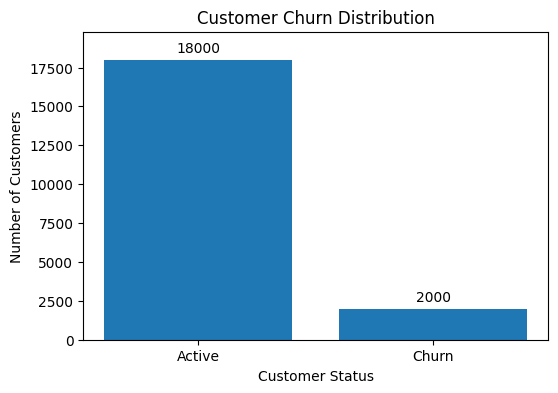

In [ ]:
# Visualize distribution of active and churned customer
import matplotlib.pyplot as plt

churn_counts = y_train.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))

# Create bars for each churn class
bars = ax.bar(
    ['Active', 'Churn'],
    churn_counts.values
)

# Add customer count labels above each bar
ax.bar_label(bars, padding=3)

# Add chart title and axis labels
ax.set_title('Customer Churn Distribution')
ax.set_xlabel('Customer Status')
ax.set_ylabel('Number of Customers')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, churn_counts.max() * 1.1)

plt.show()

In [ ]:
# Calculate percentage distribution of each churn class
churn_percentage = (
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

churn_percentage

,proportion
churn,
0,90.0
1,10.0


Finding: The dataset is imbalanced, with active customers representing 90% of the observations and churned customers representing 10%.

### ii. Categorical Features vs Churn

In [ ]:
# Calculate churn rate for each contract type
contract_churn_rate = (
    df_train_prep.groupby('contract_type')['churn']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

contract_churn_rate

,churn
contract_type,
Monthly,11.49
6 Month,6.02
12 Month,3.18


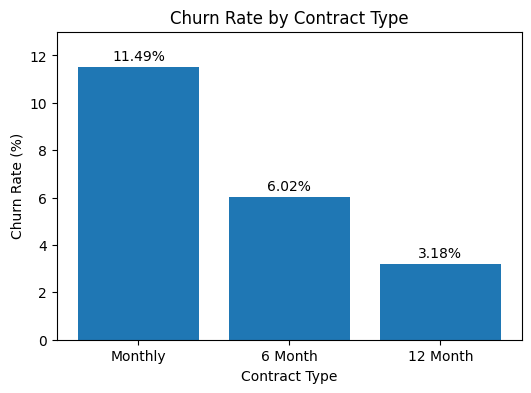

In [ ]:
# Visualize churn rate by contract type
fig, ax = plt.subplots(figsize=(6, 4))

# Create bars for each contract type
bars = ax.bar(
    contract_churn_rate.index,
    contract_churn_rate.values
)

# Add churn rate labels above each bar
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Contract Type')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, 13)

plt.show()

Churn rate differs across contract types, with the highest churn rate observed among monthly contract customers (11.49%), followed by 6-month contracts (6.02%) and 12-month contracts (3.18%).

### iii. Payment Persona vs Churn

In [ ]:
# Calculate churn rate for each payment persona
payment_churn_rate = (
    df_train_prep.groupby('payment_persona')['churn']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

payment_churn_rate

,churn
payment_persona,
LATE,35.07
NORMAL,3.61
EARLY,3.44


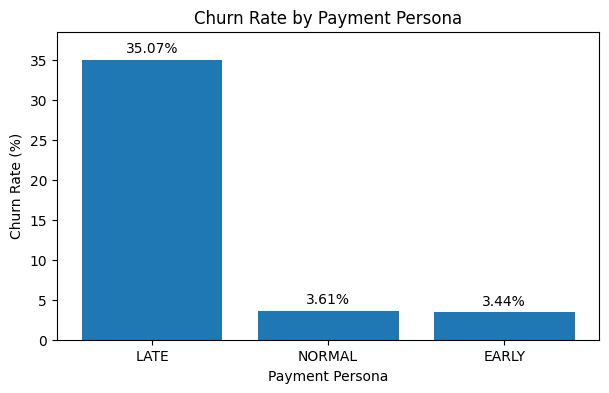

In [ ]:
# Visualize churn rate by payment persona
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each payment persona
bars = ax.bar(
    payment_churn_rate.index,
    payment_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Payment Persona')
ax.set_xlabel('Payment Persona')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, payment_churn_rate.max() * 1.1)

plt.show()

Finding: Churn rate varies substantially across payment personas. Customers classified as LATE have a churn rate of 35.07%, considerably higher than NORMAL (3.61%) and EARLY (3.44%).

### iv. District Tier vs Churn

In [ ]:
# Calculate churn rate for each district tier
district_tier_churn_rate = (
    df_train_prep.groupby('district_tier')['churn']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

district_tier_churn_rate

,churn
district_tier,
D,17.57
C,9.47
B,5.75
A,4.13


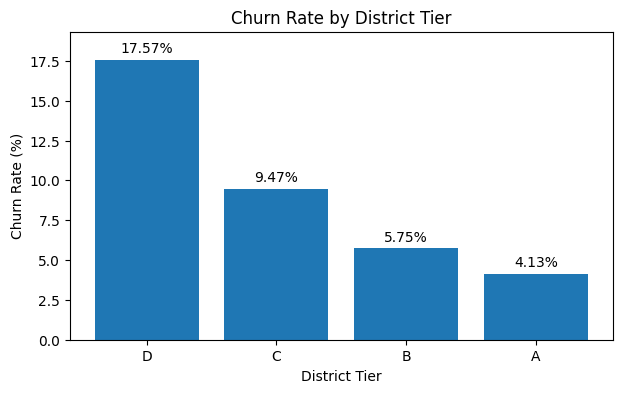

In [ ]:
# Visualize churn rate by district tier
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each district tier
bars = ax.bar(
    district_tier_churn_rate.index,
    district_tier_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by District Tier')
ax.set_xlabel('District Tier')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, district_tier_churn_rate.max() * 1.1)

plt.show()

Finding: Churn rate varies across district tiers, with the highest rate observed in Tier D (17.57%) and the lowest in Tier A (4.13%). The observed churn rates differ across the four district tier categories.

### v. Age Group vs Churn

In [ ]:
# Create age group for exploratory analysis
age_bins = [18, 30, 40, 50, 60, 100]
age_labels = ['18-29', '30-39', '40-49', '50-59', '60+']

df_train_prep['age_group'] = pd.cut(
    df_train_prep['age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

In [ ]:
# Calculate churn rate for each age group
age_churn_rate = (
    df_train_prep.groupby('age_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

age_churn_rate

,churn
age_group,
18-29,10.10
30-39,10.00
40-49,9.78
50-59,10.29
60+,9.72


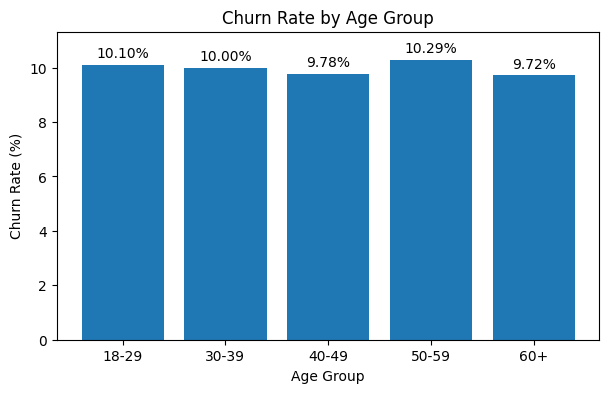

In [ ]:
# Visualize churn rate by age group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each age group
bars = ax.bar(
    age_churn_rate.index.astype(str),
    age_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, age_churn_rate.max() * 1.1)

plt.show()

Finding: Churn rates are relatively consistent across age groups, ranging from 9.72% to 10.29%. No substantial difference in churn rate is observed across the age groups.

### vi. Complaint Count vs Churn

In [ ]:
# Calculate churn rate for each complaint count
complaint_churn_rate = (
    df_train_prep.groupby('complaint_count_6m', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

complaint_churn_rate

,churn
complaint_count_6m,
0,5.57
1,13.49
2,26.05
3,35.06
4,63.64
5,100.00


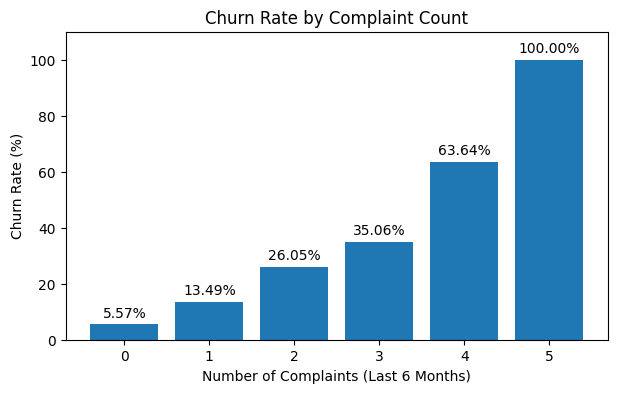

In [ ]:
# Visualize churn rate by complaint count
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each complaint count
bars = ax.bar(
    complaint_churn_rate.index.astype(str),
    complaint_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Complaint Count')
ax.set_xlabel('Number of Complaints (Last 6 Months)')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, complaint_churn_rate.max() * 1.1)

plt.show()

In [ ]:
# Check the number of customers in each complaint count
complaint_customer_count = (
    df_train_prep.groupby('complaint_count_6m', observed=True)['customer_id']
    .nunique()
)

complaint_customer_count

,customer_id
complaint_count_6m,
0,12361
1,5730
2,1566
3,308
4,33
5,2


Finding: Churn rate shows an increasing pattern as complaint count rises, from 5.57% among customers with no complaints to 35.06% among customers with three complaints. Churn rates are higher for customers with four and five complaints, but these groups contain only 33 and 2 customers respectively, so the estimates should be interpreted with caution.

### vii. Customer Satisfaction vs Churn

In [ ]:
# Check distribution of customer satisfaction scores
df_train_prep['avg_satisfaction_score_6m'].describe()

,avg_satisfaction_score_6m
count,20000.000000
mean,1.186738
std,1.611139
min,0.000000
25%,0.000000
50%,0.000000
75%,3.000000
max,5.000000


In [ ]:
# Group satisfaction scores into broader categories for EDA
satisfaction_bins = [-0.01, 1, 2, 3, 4, 5]
satisfaction_labels = [
    '0-1',
    '>1-2',
    '>2-3',
    '>3-4',
    '>4-5'
    ]

df_train_prep['satisfaction_group'] = pd.cut(
    df_train_prep['avg_satisfaction_score_6m'],
    bins=satisfaction_bins,
    labels=satisfaction_labels,
    include_lowest=True
)

In [ ]:
# Calculate churn rate for each satisfaction group
satisfaction_churn_rate = (
    df_train_prep.groupby('satisfaction_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

satisfaction_churn_rate

,churn
satisfaction_group,
0-1,5.81
>1-2,15.45
>2-3,17.43
>3-4,18.11
>4-5,16.67


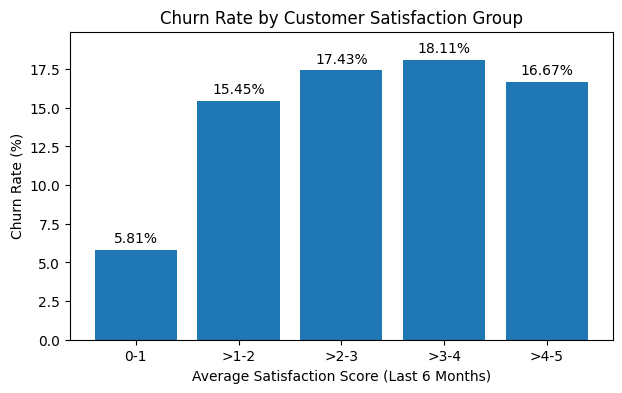

In [ ]:
# Visualize churn rate by satisfaction group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each satisfaction group
bars = ax.bar(
    satisfaction_churn_rate.index.astype(str),
    satisfaction_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Customer Satisfaction Group')
ax.set_xlabel('Average Satisfaction Score (Last 6 Months)')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, satisfaction_churn_rate.max() * 1.1)

plt.show()

Finding: Churn rate is lowest among customers with satisfaction scores of 0–1 (5.81%) and increases across the middle satisfaction groups, reaching 18.11% for scores above 3–4. The churn rate then slightly decreases to 16.67% for scores above 4–5, indicating that the relationship between satisfaction score and churn is not strictly linear.

### viii. Network Quality vs Churn

In [ ]:
# Check the distribution of network quality scores
df_train_prep['avg_quality_3m'].describe()

,avg_quality_3m
count,20000.000000
mean,75.982449
std,22.931515
min,0.000000
25%,73.200000
50%,80.433333
75%,87.900000
max,100.000000


In [ ]:
# Group network quality scores into broader categories for EDA
quality_bins = [0, 60, 70, 80, 90, 100]

quality_labels = [
    '0-60',
    '>60-70',
    '>70-80',
    '>80-90',
    '>90-100'
]

df_train_prep['quality_group'] = pd.cut(
    df_train_prep['avg_quality_3m'],
    bins=quality_bins,
    labels=quality_labels,
    include_lowest=True
)

In [ ]:
# Check the number of customers in each network quality group
quality_customer_count = (
    df_train_prep.groupby('quality_group', observed=True)['customer_id']
    .nunique()
)

quality_customer_count

,customer_id
quality_group,
0=60,1500
>60-70,630
>70-80,7247
>80-90,7393
>90-100,3230


In [ ]:
# Calculate churn rate for each network quality group
quality_churn_rate = (
    df_train_prep.groupby('quality_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

quality_churn_rate

,churn
quality_group,
0=60,96.40
>60-70,9.05
>70-80,4.43
>80-90,1.79
>90-100,1.36


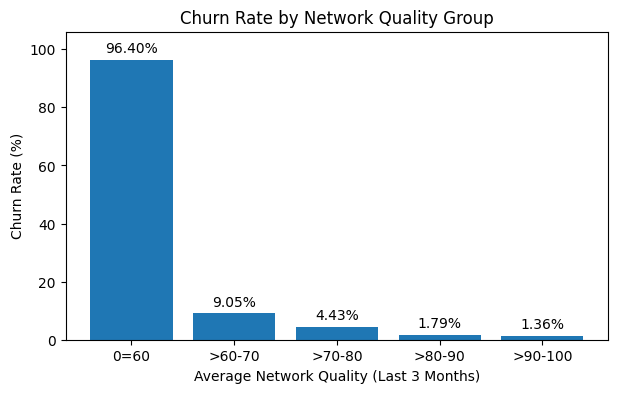

In [ ]:
# Visualize churn rate by network quality group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each network quality group
bars = ax.bar(
    quality_churn_rate.index.astype(str),
    quality_churn_rate.values
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(bars, fmt='%.2f%%', padding=3)

# Add chart title and axis labels
ax.set_title('Churn Rate by Network Quality Group')
ax.set_xlabel('Average Network Quality (Last 3 Months)')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(0, quality_churn_rate.max() * 1.1)

plt.show()

Finding: Churn rate shows a strong inverse pattern across network quality groups. Customers in the 0–60 quality group have a substantially higher observed churn rate (96.40%), while churn rates are much lower in higher quality groups, ranging from 1.36% to 9.05%.

### ix. Usage Behavior vs Churn

#### Average Usage vs Churn

In [ ]:
# Check the distribution of average usage over the last 3 months
df_train_prep['avg_usage_3m'].describe()

,avg_usage_3m
count,20000.000000
mean,512.109105
std,377.014585
min,0.000000
25%,282.102500
50%,401.593333
75%,650.648750
max,2876.020000


In [ ]:
# Group average usage into quartiles for EDA
df_train_prep['usage_group'] = pd.qcut(
    df_train_prep['avg_usage_3m'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

In [ ]:
# Check the number of customers in each usage group
usage_customer_count = (
    df_train_prep.groupby('usage_group', observed=True)['customer_id']
    .nunique()
)

usage_customer_count

,customer_id
usage_group,
Low,5000
Medium-Low,5000
Medium-High,5000
High,5000


In [ ]:
# Calculate churn rate for each usage group
usage_churn_rate = (
    df_train_prep.groupby('usage_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

usage_churn_rate

,churn
usage_group,
Low,31.10
Medium-Low,3.22
Medium-High,2.78
High,2.90


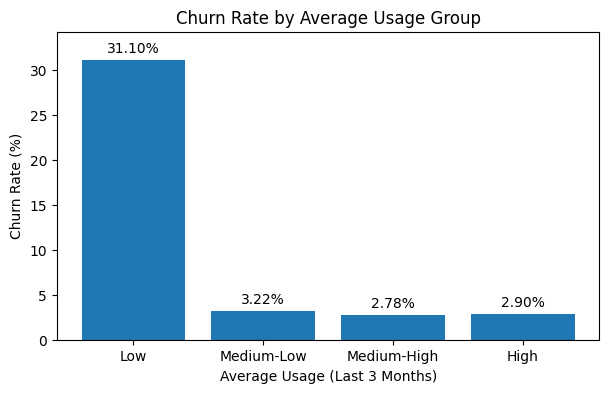

In [ ]:
# Visualize churn rate by average usage group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each usage group
bars = ax.bar(
    usage_churn_rate.index.astype(str),
    usage_churn_rate.values,
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3,
)

# Add chart title and axis labels
ax.set_title('Churn Rate by Average Usage Group')
ax.set_xlabel('Average Usage (Last 3 Months)')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(
    0,
    usage_churn_rate.max() * 1.1,
)

plt.show()

Finding: Customers in the lowest usage quartile have substantially higher churn rates (31.10%) than customers in the three higher usage groups, whose churn rates remain relatively similar at around 2.8–3.2%.

#### Average Active Days vs Churn

In [ ]:
# Check distribution of average active days over the last 3 months
df_train_prep['avg_active_days_3m'].describe()

,avg_active_days_3m
count,20000.000000
mean,22.198950
std,6.685134
min,0.000000
25%,22.000000
50%,23.666667
75%,25.333333
max,30.000000


In [ ]:
# Group average active days into quartile
df_train_prep['active_days_group'] = pd.qcut(
    df_train_prep['avg_active_days_3m'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

In [ ]:
# Check number of customers in each active days group
active_days_customer_count = (
    df_train_prep.groupby('active_days_group', observed=True)['customer_id']
    .nunique()
)

active_days_customer_count

,customer_id
active_days_group,
Low,5542
Medium-Low,4571
Medium-High,5056
High,4831


In [ ]:
# Calculate churn rate for each active days group
active_days_churn_rate = (
    df_train_prep.groupby('active_days_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

active_days_churn_rate

,churn
active_days_group,
Low,29.05
Medium-Low,1.68
Medium-High,2.53
High,3.83


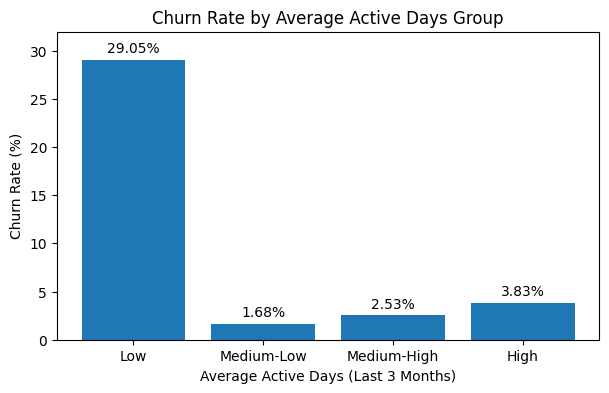

In [ ]:
# Visualize churn rate by average active days group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each active days group
bars = ax.bar(
    active_days_churn_rate.index.astype(str),
    active_days_churn_rate.values,
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3,
)

# Add chart title and axis labels
ax.set_title('Churn Rate by Average Active Days Group')
ax.set_xlabel('Average Active Days (Last 3 Months)')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(
    0,
    active_days_churn_rate.max() * 1.1,
)

plt.show()

Finding: Customers in the lowest active-days group have substantially higher churn rates (29.05%) than customers in the three higher active-days groups, whose churn rates remain relatively low at 1.68%–3.83%.

#### Previous Usage vs Churn

In [ ]:
# Check distribution of previous_usage
df_train_prep['previous_usage'].describe()

,previous_usage
count,20000.000000
mean,462.213669
std,388.991741
min,0.000000
25%,247.583333
50%,370.906667
75%,614.218333
max,2698.870000


In [ ]:
# Group previous usage into quartile
df_train_prep['previous_usage_group'] = pd.qcut(
    df_train_prep['previous_usage'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

In [ ]:
# Check number of customers in each previous usage group
previous_usage_customer_count = (
    df_train_prep.groupby('previous_usage_group', observed=True)['customer_id']
    .nunique()
)

previous_usage_customer_count

,customer_id
previous_usage_group,
Low,5000
Medium-Low,5000
Medium-High,5000
High,5000


In [ ]:
# Calculate churn rate for each previous usage group
previous_usage_churn_rate = (
    df_train_prep.groupby('previous_usage_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

previous_usage_churn_rate

,churn
previous_usage_group,
Low,30.54
Medium-Low,3.66
Medium-High,2.78
High,3.02


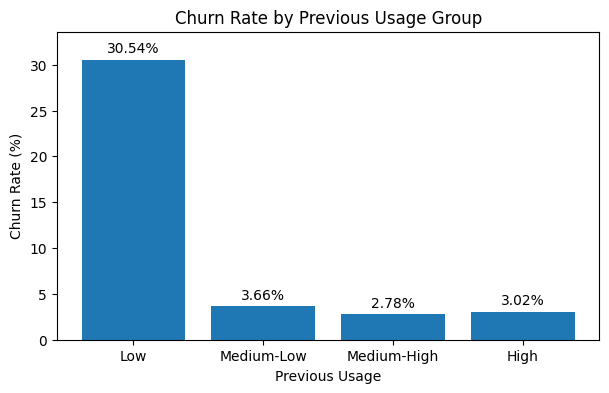

In [ ]:
# Visualize churn rate by previous usage group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each previous usage group
bars = ax.bar(
    previous_usage_churn_rate.index.astype(str),
    previous_usage_churn_rate.values,
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3,
)

# Add chart title and axis labels
ax.set_title('Churn Rate by Previous Usage Group')
ax.set_xlabel('Previous Usage')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(
    0,
    previous_usage_churn_rate.max() * 1.1,
)

plt.show()

Finding: Customers in the lowest previous-usage group have substantially higher churn rates (30.54%) than customers in the three higher groups, whose churn rates remain relatively low at 2.78%–3.66%.

#### Usage Ratio vs Churn

In [ ]:
# Check distribution of usage ration
df_train_prep['usage_ratio'].describe()

,usage_ratio
count,20000.000000
mean,0.930260
std,0.289929
min,0.000000
25%,0.900766
50%,1.000000
75%,1.067252
max,1.806829


In [ ]:
# Group usage ratio into quartile
df_train_prep['usage_ratio_group'] = pd.qcut(
    df_train_prep['usage_ratio'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

In [ ]:
# Check number of customers in each usage ratio group
usage_ratio_customer_count = (
    df_train_prep.groupby('usage_ratio_group', observed=True)['customer_id']
    .nunique()
)
usage_ratio_customer_count

,customer_id
usage_ratio_group,
Low,5000
Medium-Low,6757
Medium-High,3243
High,5000


In [ ]:
# Calculate churn rate for each usage ratio group
usage_ratio_churn_rate = (
    df_train_prep.groupby('usage_ratio_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

usage_ratio_churn_rate

,churn
usage_ratio_group,
Low,31.48
Medium-Low,2.43
Medium-High,2.47
High,3.64


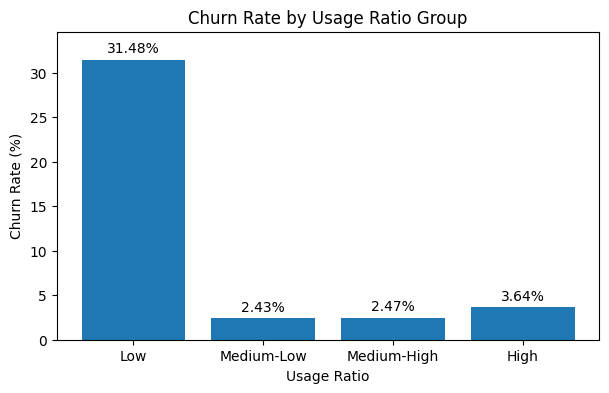

In [ ]:
# Visualize churn rate by usage ratio group
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each usage ratio group
bars = ax.bar(
    usage_ratio_churn_rate.index.astype(str),
    usage_ratio_churn_rate.values,
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3,
)

# Add chart title and axis labels
ax.set_title('Churn Rate by Usage Ratio Group')
ax.set_xlabel('Usage Ratio')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(
    0,
    usage_ratio_churn_rate.max() * 1.1,
)

plt.show()

Finding: Customers in the lowest usage-ratio group have substantially higher churn rates (31.48%) than customers in the three higher groups, whose churn rates remain relatively low at 2.43%–3.64%.

### x. Customer Lifecycle vs Churn

In [ ]:
# Check distribution of customer tenure
df_train_prep['tenure_months'].describe()

,tenure_months
count,20000.000000
mean,10.320350
std,4.996266
min,0.000000
25%,6.000000
50%,12.000000
75%,15.000000
max,17.000000


In [ ]:
# Group customer tenure into lifecycle stage
tenure_bins = [-1, 6, 12, 17]
tenure_labels = ['0-6 Months', '7-12 Months', '13-17 Months']

df_train_prep['lifecycle_stage'] = pd.cut(
    df_train_prep['tenure_months'],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

In [ ]:
# Check number of customers in each lifecycle stage
lifecycle_customer_count = (
    df_train_prep.groupby('lifecycle_stage', observed=True)['customer_id']
    .nunique()
)

lifecycle_customer_count

,customer_id
lifecycle_stage,
0-6 Months,5009
7-12 Months,6606
13-17 Months,8385


In [ ]:
# Calculate churn rate for each customer lifecycle stage
lifecycle_churn_rate = (
    df_train_prep.groupby('lifecycle_stage', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
)

lifecycle_churn_rate

,churn
lifecycle_stage,
0-6 Months,14.37
7-12 Months,10.26
13-17 Months,7.18


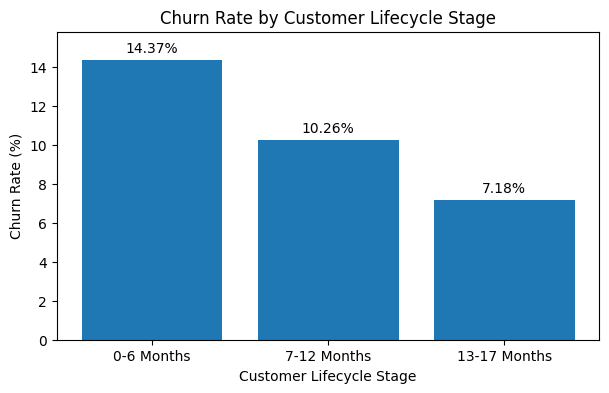

In [ ]:
# Visualize churn rate by customer lifecycle stage
fig, ax = plt.subplots(figsize=(7, 4))

# Create bars for each lifecycle stage
bars = ax.bar(
    lifecycle_churn_rate.index.astype(str),
    lifecycle_churn_rate.values,
)

# Add churn rate labels above each bar with two decimal places
ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3,
)

# Add chart title and axis labels
ax.set_title('Churn Rate by Customer Lifecycle Stage')
ax.set_xlabel('Customer Lifecycle Stage')
ax.set_ylabel('Churn Rate (%)')

# Add extra space above the bars so the labels do not overlap with the chart border
ax.set_ylim(
    0,
    lifecycle_churn_rate.max() * 1.1,
)

plt.show()

Finding: Observed churn rate decreases across customer lifecycle stages, from 14.37% among customers with 0–6 months of tenure to 10.26% for 7–12 months and 7.18% for 13–17 months.

### xi. EDA Summary

Based on the exploratory analysis, several patterns can be observed across customer characteristics, behavior, experience, and lifecycle.

• The dataset contains 20,000 customers, with 10% churned customers and 90% active customers.
• Churn varies across contract types, with Monthly customers showing a higher observed churn rate than customers with longer-term contracts.
• Payment behavior shows a noticeable difference in churn, with the LATE payment persona having the highest observed churn rate.
• Churn rates vary across district tiers, with Tier D showing the highest observed churn rate among the four tiers.
• Age groups show relatively similar churn rates, with no substantial difference observed across age groups.
• Customers with more complaints tend to have higher observed churn rates. However, groups with a high number of complaints contain fewer customers and should be interpreted carefully.
• Network quality shows a strong pattern with churn. Customers in the lowest network quality group have substantially higher observed churn rates.
• Usage and engagement features show a consistent pattern. Customers in the lowest groups of average usage, active days, previous usage, and usage ratio have much higher observed churn rates than customers in the higher groups.
• Customer tenure also shows a pattern, where observed churn rate decreases across tenure groups.
• Satisfaction score does not show a clear linear relationship with churn, as the observed churn rate varies across satisfaction groups.

Overall, the EDA suggests that customer engagement, network quality, payment behavior, contract type, complaints, and tenure may provide useful information for predicting churn. These findings will be considered in the next stage of feature engineering and modeling.

## **K. Feature Selection & Diagnostics**

In [ ]:
# Review current feature columns before feature engineering
feature_columns

['gender',
 'age',
 'city',
 'district',
 'district_tier',
 'join_date',
 'installation_days',
 'tenure_months',
 'household_size',
 'connected_devices',
 'payment_persona',
 'package_speed_mbps',
 'monthly_fee',
 'contract_type',
 'activation_date',
 'complaint_count_6m',
 'avg_resolution_days_6m',
 'avg_satisfaction_score_6m',
 'avg_quality_3m',
 'avg_downtime_3m',
 'avg_latency_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'avg_usage_3m',
 'avg_active_days_3m',
 'previous_usage',
 'usage_ratio']

### i. Review Feature Data Types

In [ ]:
# Check data type of each feature before preprocessing
df_train_prep[feature_columns].dtypes

,0
gender,object
age,int64
city,object
district,object
district_tier,object
join_date,datetime64[ns]
installation_days,int64
tenure_months,int64
household_size,int64
connected_devices,int64


**Decision:** The initial feature set was reviewed to identify relevant features and potential redundancies before preprocessing.

### ii. Categorical Feature Check

In [ ]:
# Check the unique values of each categorical feature
for col in categorical_features:
    print(f'{col}: {df_train_prep[col].unique()}')

gender: ['Male' 'Female']
city: ['Jakarta Timur' 'Jakarta Barat' 'Jakarta Selatan' 'Jakarta Utara'
 'Jakarta Pusat' 'Kepulauan Seribu']
district: ['Jatinegara' 'Ciracas' 'Kramat Jati' 'Duren Sawit' 'Cakung' 'Cengkareng'
 'Kebon Jeruk' 'Palmerah' 'Kembangan' 'Kalideres' 'Jagakarsa' 'Tebet'
 'Kebayoran Baru' 'Pasar Minggu' 'Pancoran' 'Penjaringan' 'Koja'
 'Kelapa Gading' 'Tanjung Priok' 'Cilincing' 'Cempaka Putih' 'Kemayoran'
 'Tanah Abang' 'Menteng' 'Johar Baru' 'Kepulauan Seribu Selatan'
 'Kepulauan Seribu Utara']
district_tier: ['C' 'D' 'B' 'A']
payment_persona: ['NORMAL' 'EARLY' 'LATE']
contract_type: ['Monthly' '12 Month' '6 Month']


In [ ]:
# Review date features before deciding how to use them
df_train_prep[['join_date', 'activation_date']].describe()

,join_date,activation_date
count,20000,20000
mean,2025-08-05 03:19:00.480000256,2025-08-10 02:43:17.760000256
min,2025-01-01 00:00:00,2025-01-02 00:00:00
25%,2025-03-31 00:00:00,2025-04-05 00:00:00
50%,2025-06-28 00:00:00,2025-07-03 00:00:00
75%,2025-11-30 00:00:00,2025-12-04 00:00:00
max,2026-06-30 00:00:00,2026-07-12 00:00:00


In [ ]:
# Calculate the number of days between joining and activation
date_difference = (
    df_train_prep['activation_date'] - df_train_prep['join_date']
).dt.days

date_difference.describe()

,0
count,20000.000000
mean,4.975200
std,3.129469
min,1.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,14.000000


In [ ]:
# Check whether the date difference duplicates the exxisting installation_days before
(date_difference == df_train_prep['installation_days']).all()

np.True_

**Decision:** Six categorical features were identified, and their unique values were checked to confirm that the categories were valid and consistent.

### iii. Finalize Date Features

In [ ]:
# remove all date features because their information is already represented by installation_days
feature_columns = [
    col for col in feature_columns
    if col not in ['join_date', 'activation_date']
]

In [ ]:
# Review update feature columns after removing raw date features
feature_columns

['gender',
 'age',
 'city',
 'district',
 'district_tier',
 'installation_days',
 'tenure_months',
 'household_size',
 'connected_devices',
 'payment_persona',
 'package_speed_mbps',
 'monthly_fee',
 'contract_type',
 'complaint_count_6m',
 'avg_resolution_days_6m',
 'avg_satisfaction_score_6m',
 'avg_quality_3m',
 'avg_downtime_3m',
 'avg_latency_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'avg_usage_3m',
 'avg_active_days_3m',
 'previous_usage',
 'usage_ratio']

In [ ]:
# Identify categorical and numerical features for preprocessing
categorical_features = df_train_prep[feature_columns].select_dtypes(include=['object']).columns.tolist()
numerical_features = df_train_prep[feature_columns].select_dtypes(include=['int64', 'float64']).columns.tolist()

In [ ]:
# Review categorical and numerical feature lists
print(f'Categorical Features: {categorical_features}')
print(f'Numerical Features: {numerical_features}')

Categorical Features: ['gender', 'city', 'district', 'district_tier', 'payment_persona', 'contract_type']
Numerical Features: ['age', 'installation_days', 'tenure_months', 'household_size', 'connected_devices', 'package_speed_mbps', 'monthly_fee', 'complaint_count_6m', 'avg_resolution_days_6m', 'avg_satisfaction_score_6m', 'avg_quality_3m', 'avg_downtime_3m', 'avg_latency_3m', 'avg_late_payment_days_6m', 'total_late_count_6m', 'avg_usage_3m', 'avg_active_days_3m', 'previous_usage', 'usage_ratio']


**Decision:** `join_date` and `activation_date` were excluded from the modeling features because the difference between the two dates is identical to `installation_days`, which already captures the same information.

### iv. Missing Value Check

In [ ]:
# Check missing value in the final modeling features
df_train_prep[feature_columns].isnull().sum().sort_values(ascending=False)

,0
gender,0
age,0
city,0
district,0
district_tier,0
installation_days,0
tenure_months,0
household_size,0
connected_devices,0
payment_persona,0


**Decision:** No missing values were found in the final modeling features, so no imputation is required.

### v. Derived Feature Engineering

Additional features are created based on the feature engineering approach used in the reference notebook. Redundant features are not duplicated when the same information is already represented by an existing feature.

In [ ]:
# Calculate the approximate number of months each customer has been a member
j_date = pd.to_datetime(df_train_prep['join_date'])
a_date = pd.to_datetime(df_train_prep['activation_date'])
present_day = (a_date + pd.to_timedelta(
    df_train_prep['tenure_months'] * 30.44,
    unit='D')).max()

df_train_prep['month_of_member'] = ((present_day - j_date).dt.days / 30.44)

In [ ]:
# Review the distribution of the newly created month_of_member feature
df_train_prep['month_of_member'].describe()

,month_of_member
count,20000.000000
mean,11.263528
std,4.995463
min,0.459921
25%,7.424442
50%,12.516426
75%,15.440210
max,18.363995


In [ ]:
# Group customers into 5 tenure buckets based on month_of_member quantiles
train_labels = [
    'q1_0_6m',
    'q2_6_10m',
    'q3_10_13m',
    'q4_13_16m',
    'q5_16m_plus',
]

df_train_prep['tenure_bucket'], train_bins = pd.qcut(
    df_train_prep['month_of_member'],
    q=5,
    labels=train_labels,
    retbins=True,
)

# Make the first and last boundaries universal for the test dataset
train_bins[0] = -np.inf
train_bins[-1] = np.inf

In [ ]:
# Check the number of customers in each tenure bucket
df_train_prep['tenure_bucket'].value_counts().sort_index()

,count
tenure_bucket,
q1_0_6m,4012
q2_6_10m,3998
q3_10_13m,4015
q4_13_16m,4008
q5_16m_plus,3967


**Decision:** `tenure_bucket` will be retained as an additional categorical feature, with the training bucket boundaries stored in `train_bins` to ensure consistent bucketing when applied to the test data.

### vi. Feature Selection & Distribution

Feature selection is performed by considering the patterns identified during EDA and the feature importance results from the baseline XGBoost model. Features with stronger predictive relevance and clear business interpretability are considered as candidate features for the next modeling stage.

#### Boxplot Analysis

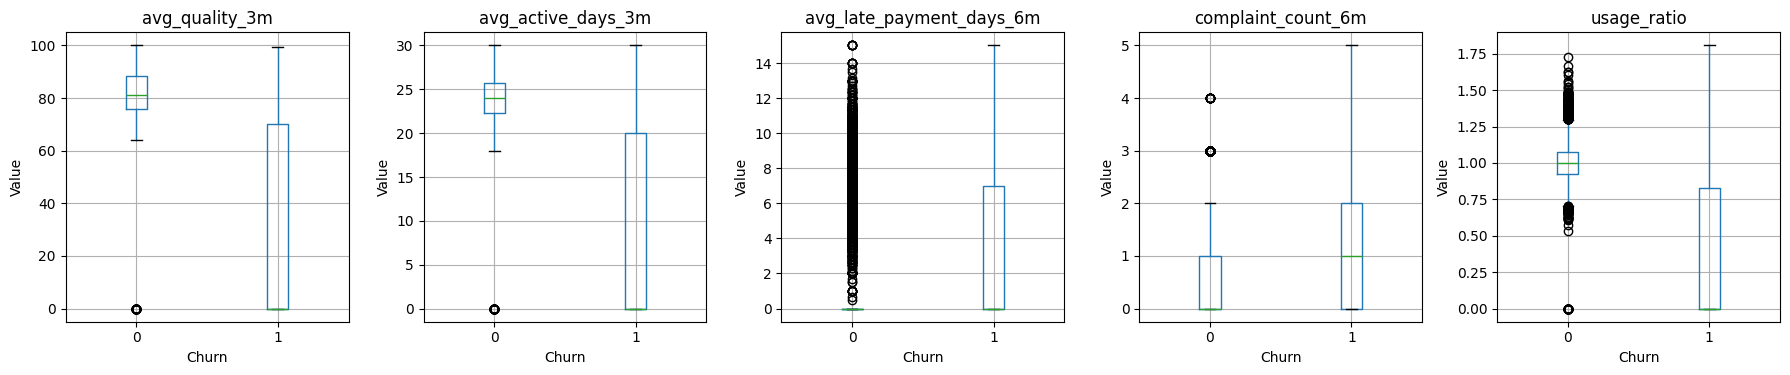

In [ ]:
# Select key numerical features for boxplot analysis
boxplot_features = [
    'avg_quality_3m',
    'avg_active_days_3m',
    'avg_late_payment_days_6m',
    'complaint_count_6m',
    'usage_ratio',
]

# Create boxplots to compare feature distributions by churn status
fig, axes = plt.subplots(
    1,
    5,
    figsize=(18, 4),
)

# Plot each feature against churn status
for ax, feature in zip(axes, boxplot_features):
    df_train_prep.boxplot(
        column=feature,
        by='churn',
        ax=ax,
    )
    ax.set_title(feature)
    ax.set_xlabel('Churn')
    ax.set_ylabel('Value')

# Remove the default pandas title and adjust the layout
plt.suptitle('')
plt.tight_layout()
plt.show()

#### Candidate Feature Selection

In [ ]:
# Select candidate features based on EDA, feature importance, and boxplot analysis
candidate_features = [
    'avg_quality_3m',
    'avg_active_days_3m',
    'avg_late_payment_days_6m',
    'total_late_count_6m',
    'complaint_count_6m',
    'usage_ratio',
    'avg_resolution_days_6m',
    'contract_type',
]

candidate_features

['avg_quality_3m',
 'avg_active_days_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'complaint_count_6m',
 'usage_ratio',
 'avg_resolution_days_6m',
 'contract_type']

#### Feature Selection Summary

In [ ]:
# Review the final list and number of candidate features
print(f'Total candidate features: {len(candidate_features)}')
print('\nCandidate features:')
for feature in candidate_features:
    print(f'- {feature}')

Total candidate features: 8

Candidate features:
- avg_quality_3m
- avg_active_days_3m
- avg_late_payment_days_6m
- total_late_count_6m
- complaint_count_6m
- usage_ratio
- avg_resolution_days_6m
- contract_type


Finding: Based on the EDA findings, boxplot analysis, and business relevance, 8 candidate features were selected for further modeling. These features represent customer network quality, engagement, payment behavior, complaints, usage, service experience, and contract type.

### vii. Categorical Encoding

#### Define Modeling Features

In [ ]:
# Define the selected candidate features for model development
final_feature_columns = candidate_features

final_feature_columns

['avg_quality_3m',
 'avg_active_days_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'complaint_count_6m',
 'usage_ratio',
 'avg_resolution_days_6m',
 'contract_type']

#### Encode categorical features

In [ ]:
# Define categorical features among the selected candidate features
categorical_features = ['contract_type']

categorical_features

['contract_type']

#### One-Hot Encoding

In [ ]:
# Apply one-hot encoding to the final modeling features
df_train_encoded = pd.get_dummies(
    df_train_prep[final_feature_columns],
    columns=categorical_features,
    dtype=int,
)

#### Review Hasil Encoding

In [ ]:
# Review the shape and columns after one-hot encoding
print('Shape before encoding:', df_train_prep[final_feature_columns].shape)
print('Shape after encoding:', df_train_encoded.shape)

df_train_encoded.columns.tolist()

Shape before encoding: (20000, 8)
Shape after encoding: (20000, 10)


['avg_quality_3m',
 'avg_active_days_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'complaint_count_6m',
 'usage_ratio',
 'avg_resolution_days_6m',
 'contract_type_12 Month',
 'contract_type_6 Month',
 'contract_type_Monthly']

**Decision:** The selected 8 candidate features were prepared for modeling, with contract_type transformed using one-hot encoding. This resulted in 10 modeling features while retaining all 20,000 customers.

### viii. Train-Test Feature Consistency

#### One-Hot Encoding Test Data

In [ ]:
# Apply the same one-hot encoding to the final test features
df_test_encoded = pd.get_dummies(
    df_test_prep[final_feature_columns],
    columns=categorical_features,
    dtype=int,
)

#### Compare Train & Test Feature

In [ ]:
# Compare feature columns between training and test data
print('Train shape:', df_train_encoded.shape)
print('Test shape:', df_test_encoded.shape)

print('\nTrain columns missing from test:')
print(df_train_encoded.columns.difference(df_test_encoded.columns).tolist())

print('\nTest columns missing from train:')
print(df_test_encoded.columns.difference(df_train_encoded.columns).tolist())

Train shape: (20000, 10)
Test shape: (4000, 10)

Train columns missing from test:
[]

Test columns missing from train:
[]


#### Verify Column Order

In [ ]:
# Verify that training and test feature columns have the same order
df_train_encoded.columns.equals(df_test_encoded.columns)

True

Decision: The training and test datasets have consistent feature columns and column order after preprocessing, with 10 features in both datasets. The same feature structure will be maintained for model development and evaluation.

## **L. Model Development**

### i. Prepare Modeling Data

In [ ]:
# Prepare the final training features and target variable
X_train = df_train_encoded.copy()
y_train = df_train_prep['churn'].copy()

X_train.shape, y_train.shape

((20000, 10), (20000,))

### ii. Train / Validation Strategy

#### Split Training Data

In [ ]:
# Split training data into development and validation sets
from sklearn.model_selection import train_test_split

X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,
)

print('X development:', X_dev.shape)
print('X validation:', X_val.shape)
print('y development:', y_dev.shape)
print('y validation:', y_val.shape)

X development: (16000, 10)
X validation: (4000, 10)
y development: (16000,)
y validation: (4000,)


#### Check Stratification

In [ ]:
# Check churn distribution in development and validation sets
print('Development churn rate:')
print(y_dev.value_counts(normalize=True).mul(100).round(2))

print('\nValidation churn rate:')
print(y_val.value_counts(normalize=True).mul(100).round(2))

Development churn rate:
churn
0    90.0
1    10.0
Name: proportion, dtype: float64

Validation churn rate:
churn
0    90.0
1    10.0
Name: proportion, dtype: float64


Decision: The training data was split into development and validation sets using stratified sampling, preserving the original 90% active and 10% churn distribution in both subsets. The test set remains untouched for final evaluation.

### iii. Logistic Regression Baseline

In [ ]:
# Scale development and validation features using the same scaler
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on development data and transform it
X_dev_scaled = scaler.fit_transform(X_dev)

# Transform validation data using the same scaler
X_val_scaled = scaler.transform(X_val)

#### Train Logistic Regression

In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression baseline model
logreg_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

# Train the model using the scaled development data
logreg_model.fit(
    X_dev_scaled,
    y_dev,
)

LogisticRegression(max_iter=1000, random_state=42)

#### Generate Validation Predictions

In [ ]:
# Generate churn predictions on the validation data
y_val_pred = logreg_model.predict(X_val_scaled)

# Generate churn probabilities for ROC-AUC evaluation
y_val_proba = logreg_model.predict_proba(X_val_scaled)[:, 1]

print('Predicted class shape:', y_val_pred.shape)
print('Predicted probability shape:', y_val_proba.shape)

Predicted class shape: (4000,)
Predicted probability shape: (4000,)


#### Evaluate Logistic Regression Baseline

In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Calculate classification metrics
logreg_accuracy = accuracy_score(y_val, y_val_pred)
logreg_precision = precision_score(y_val, y_val_pred)
logreg_recall = recall_score(y_val, y_val_pred)
logreg_f1 = f1_score(y_val, y_val_pred)

# Calculate ROC-AUC using churn probabilities
logreg_roc_auc = roc_auc_score(y_val, y_val_proba)

# Display the baseline performance
print('Logistic Regression Baseline')
print(f'Accuracy : {logreg_accuracy:.4f}')
print(f'Precision: {logreg_precision:.4f}')
print(f'Recall   : {logreg_recall:.4f}')
print(f'F1-score : {logreg_f1:.4f}')
print(f'ROC-AUC  : {logreg_roc_auc:.4f}')

Logistic Regression Baseline
Accuracy : 0.9690
Precision: 0.9340
Recall   : 0.7425
F1-score : 0.8273
ROC-AUC  : 0.9643


Decision: Logistic Regression achieved an accuracy of 96.90%, precision of 93.40%, recall of 74.25%, F1-score of 82.73%, and ROC-AUC of 96.43% on the validation set. These results will be used as the baseline for comparison with other candidate models.

### iv. Random Forest Baseline

#### Train Random Forest

In [ ]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest baseline model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
)

# Train the model using the development data
rf_model.fit(
    X_dev,
    y_dev,
)

RandomForestClassifier(random_state=42)

#### Generate Validation Predictions

In [ ]:
# Generate churn predictions on the validation data
y_val_pred = rf_model.predict(X_val)

# Generate churn probabilities for ROC-AUC evaluation
y_val_proba = rf_model.predict_proba(X_val)[:, 1]

# Check the prediction output shapes
print('Predicted class shape:', y_val_pred.shape)
print('Predicted probability shape:', y_val_proba.shape)

Predicted class shape: (4000,)
Predicted probability shape: (4000,)


#### Evaluate Random Forest Baseline

In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Calculate classification metrics
rf_accuracy = accuracy_score(y_val, y_val_pred)
rf_precision = precision_score(y_val, y_val_pred)
rf_recall = recall_score(y_val, y_val_pred)
rf_f1 = f1_score(y_val, y_val_pred)

# Calculate ROC-AUC using churn probabilities
rf_roc_auc = roc_auc_score(y_val, y_val_proba)

# Display the baseline performance
print('Random Forest Baseline')
print(f'Accuracy : {rf_accuracy:.4f}')
print(f'Precision: {rf_precision:.4f}')
print(f'Recall   : {rf_recall:.4f}')
print(f'F1-score : {rf_f1:.4f}')
print(f'ROC-AUC  : {rf_roc_auc:.4f}')

Random Forest Baseline
Accuracy : 0.9738
Precision: 0.9377
Recall   : 0.7900
F1-score : 0.8575
ROC-AUC  : 0.9601


Decision: Random Forest achieved an accuracy of 97.38%, precision of 93.77%, recall of 79.00%, F1-score of 85.75%, and ROC-AUC of 96.01% on the validation set. These results will be compared with the other candidate models using the same selected feature set.

### v. XGBoost Baseline

#### Train XGBoost

In [ ]:
# Import XGBoost classifier
from xgboost import XGBClassifier

# Initialize the XGBoost baseline model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
)

# Train the model using the development data
xgb_model.fit(
    X_dev,
    y_dev,
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

#### Generate Validation Predictions

In [ ]:
# Generate churn predictions on the validation data
y_val_pred = xgb_model.predict(X_val)

# Generate churn probabilities for ROC-AUC evaluation
y_val_proba = xgb_model.predict_proba(X_val)[:, 1]

# Check the prediction output shapes
print('Predicted class shape:', y_val_pred.shape)
print('Predicted probability shape:', y_val_proba.shape)

Predicted class shape: (4000,)
Predicted probability shape: (4000,)


#### Evaluate XGBoost Baseline

In [ ]:
# Calculate classification metrics
xgb_accuracy = accuracy_score(y_val, y_val_pred)
xgb_precision = precision_score(y_val, y_val_pred)
xgb_recall = recall_score(y_val, y_val_pred)
xgb_f1 = f1_score(y_val, y_val_pred)

# Calculate ROC-AUC using churn probabilities
xgb_roc_auc = roc_auc_score(y_val, y_val_proba)

# Display the baseline performance
print('XGBoost Baseline')
print(f'Accuracy : {xgb_accuracy:.4f}')
print(f'Precision: {xgb_precision:.4f}')
print(f'Recall   : {xgb_recall:.4f}')
print(f'F1-score : {xgb_f1:.4f}')
print(f'ROC-AUC  : {xgb_roc_auc:.4f}')

XGBoost Baseline
Accuracy : 0.9718
Precision: 0.9335
Recall   : 0.7725
F1-score : 0.8454
ROC-AUC  : 0.9715


Decision: XGBoost achieved an accuracy of 97.18%, precision of 93.35%, recall of 77.25%, F1-score of 84.54%, and ROC-AUC of 97.15% on the validation set. These results will be compared with the other baseline models before proceeding to hyperparameter optimization.

## **M. Hyperparameter Optimization**

### i. Define Tuning Strategy

In [ ]:
# Import tools for hyperparameter optimization
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV

# Define the scoring metric for hyperparameter optimization
tuning_scoring = 'roc_auc'

# Define stratified 5-fold cross-validation strategy
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Review the tuning strategy
print('Tuning metric:', tuning_scoring)
print('Cross-validation:', cv_strategy)

Tuning metric: roc_auc
Cross-validation: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


Finding: ROC-AUC is used as the primary metric for hyperparameter optimization. Stratified 5-fold cross-validation is applied to maintain the churn class distribution across folds.

### ii. Tune Logistic Regression

#### Define Hyperparameter Search Space

In [ ]:
# Define the Logistic Regression hyperparameter search space
logreg_param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs'],
    'max_iter': [1000],
}

# Review the hyperparameter search space
logreg_param_grid

{'C': [0.01, 0.1, 1, 10], 'solver': ['lbfgs'], 'max_iter': [1000]}

#### Run GridSearchCV

In [ ]:
# Initialize Logistic Regression for hyperparameter tuning
logreg_tuning_model = LogisticRegression(
    random_state=42,
)

# Run GridSearchCV on the development data
logreg_search = GridSearchCV(
    estimator=logreg_tuning_model,
    param_grid=logreg_param_grid,
    scoring=tuning_scoring,
    cv=cv_strategy,
    n_jobs=-1,
)

# Fit GridSearchCV using the scaled development data
logreg_search.fit(
    X_dev_scaled,
    y_dev,
)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10], 'max_iter': [1000],
                         'solver': ['lbfgs']},
             scoring='roc_auc')

#### Review Best Parameters & CV Score

In [ ]:
# Review the best Logistic Regression parameters
print('Best Logistic Regression Parameters:')
print(logreg_search.best_params_)

# Review the best cross-validation ROC-AUC
print('\nBest CV ROC-AUC:')
print(f'{logreg_search.best_score_:.4f}')

Best Logistic Regression Parameters:
{'C': 1, 'max_iter': 1000, 'solver': 'lbfgs'}

Best CV ROC-AUC:
0.9727


#### Evaluate Optimized Logistic Regression

In [ ]:
# Get the best Logistic Regression model
best_logreg = logreg_search.best_estimator_

# Generate churn predictions on the validation data
logreg_tuned_pred = best_logreg.predict(X_val_scaled)

# Generate churn probabilities for ROC-AUC evaluation
logreg_tuned_proba = best_logreg.predict_proba(X_val_scaled)[:, 1]

# Calculate validation metrics
logreg_tuned_accuracy = accuracy_score(y_val, logreg_tuned_pred)
logreg_tuned_precision = precision_score(y_val, logreg_tuned_pred)
logreg_tuned_recall = recall_score(y_val, logreg_tuned_pred)
logreg_tuned_f1 = f1_score(y_val, logreg_tuned_pred)
logreg_tuned_roc_auc = roc_auc_score(y_val, logreg_tuned_proba)

# Display optimized Logistic Regression performance
print('Optimized Logistic Regression')
print(f'Accuracy : {logreg_tuned_accuracy:.4f}')
print(f'Precision: {logreg_tuned_precision:.4f}')
print(f'Recall   : {logreg_tuned_recall:.4f}')
print(f'F1-score : {logreg_tuned_f1:.4f}')
print(f'ROC-AUC  : {logreg_tuned_roc_auc:.4f}')

Optimized Logistic Regression
Accuracy : 0.9690
Precision: 0.9340
Recall   : 0.7425
F1-score : 0.8273
ROC-AUC  : 0.9643


Decision: GridSearchCV identified C=1, solver='lbfgs', and max_iter=1000 as the best Logistic Regression configuration, with a cross-validation ROC-AUC of 0.9727. On the validation set, the optimized model achieved a ROC-AUC of 0.9643, the same as the baseline model. The optimized Logistic Regression will be compared with other optimized models before selecting the final model.

### iii. Tune Random Forest

#### Define Hyperparameter Search Space

In [ ]:
# Define the Random Forest hyperparameter search space
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced'],
}

# Review the hyperparameter search space
rf_param_grid

{'n_estimators': [100, 200, 300],
 'max_depth': [None, 10, 20],
 'min_samples_split': [2, 5],
 'min_samples_leaf': [1, 2],
 'max_features': ['sqrt', 'log2'],
 'class_weight': [None, 'balanced']}

#### Run RandomizedSearchCV

In [ ]:
# Initialize Random Forest for hyperparameter tuning
rf_tuning_model = RandomForestClassifier(
    random_state=42,
)

# Run RandomizedSearchCV on the development data
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=rf_param_grid,
    n_iter=20,
    scoring=tuning_scoring,
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
)

# Fit RandomizedSearchCV using the development data
rf_search.fit(
    X_dev,
    y_dev,
)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=RandomForestClassifier(random_state=42), n_iter=20,
                   n_jobs=-1,
                   param_distributions={'class_weight': [None, 'balanced'],
                                        'max_depth': [None, 10, 20],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [100, 200, 300]},
                   random_state=42, scoring='roc_auc')

#### Review Best Parameters & CV Score

In [ ]:
# Review the best Random Forest parameters
print('Best Random Forest Parameters:')
print(rf_search.best_params_)

# Review the best cross-validation ROC-AUC
print('\nBest CV ROC-AUC:')
print(f'{rf_search.best_score_:.4f}')

Best Random Forest Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': None}

Best CV ROC-AUC:
0.9780


#### Evaluate Optimized Random Forest

In [ ]:
# Get the best Random Forest model
best_rf = rf_search.best_estimator_

# Generate churn predictions on the validation data
rf_tuned_pred = best_rf.predict(X_val)

# Generate churn probabilities for ROC-AUC evaluation
rf_tuned_proba = best_rf.predict_proba(X_val)[:, 1]

# Calculate validation metrics
rf_tuned_accuracy = accuracy_score(y_val, rf_tuned_pred)
rf_tuned_precision = precision_score(y_val, rf_tuned_pred)
rf_tuned_recall = recall_score(y_val, rf_tuned_pred)
rf_tuned_f1 = f1_score(y_val, rf_tuned_pred)
rf_tuned_roc_auc = roc_auc_score(y_val, rf_tuned_proba)

# Display optimized Random Forest performance
print('Optimized Random Forest')
print(f'Accuracy : {rf_tuned_accuracy:.4f}')
print(f'Precision: {rf_tuned_precision:.4f}')
print(f'Recall   : {rf_tuned_recall:.4f}')
print(f'F1-score : {rf_tuned_f1:.4f}')
print(f'ROC-AUC  : {rf_tuned_roc_auc:.4f}')

Optimized Random Forest
Accuracy : 0.9730
Precision: 0.9398
Recall   : 0.7800
F1-score : 0.8525
ROC-AUC  : 0.9685


Decision: RandomizedSearchCV identified 100 estimators, max depth of 10, minimum samples split of 5, minimum samples leaf of 1, sqrt max features, and no class weighting as the best Random Forest configuration, with a cross-validation ROC-AUC of 0.9780. On the validation set, the optimized model achieved an accuracy of 97.30%, precision of 93.98%, recall of 78.00%, F1-score of 85.25%, and ROC-AUC of 96.85%. The optimized Random Forest will be compared with other optimized models before selecting the final model.

### iv. Tune XGBoost

#### Define Hyperparameter Search Space

In [ ]:
# Define the XGBoost hyperparameter search space
xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}

# Review the hyperparameter search space
xgb_param_grid

{'n_estimators': [100, 200, 300],
 'max_depth': [3, 5, 7],
 'learning_rate': [0.01, 0.05, 0.1],
 'subsample': [0.8, 1.0],
 'colsample_bytree': [0.8, 1.0]}

#### Run RandomizedSearchCV

In [ ]:
# Initialize XGBoost for hyperparameter tuning
xgb_tuning_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
)

# Run RandomizedSearchCV on the development data
xgb_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=xgb_param_grid,
    n_iter=10,
    scoring=tuning_scoring,
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
)

# Fit RandomizedSearchCV using the development data
xgb_search.fit(
    X_dev,
    y_dev,
)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,...
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [100, 200, 300],
                                        'subsample': [0.8, 1.0]},
                   random_state=42, scoring='roc_auc')

#### Review Best Parameters & CV Score

In [ ]:
# Review the best XGBoost parameters
print('Best XGBoost Parameters:')
print(xgb_search.best_params_)

# Review the best cross-validation ROC-AUC
print('\nBest CV ROC-AUC:')
print(f'{xgb_search.best_score_:.4f}')

Best XGBoost Parameters:
{'subsample': 1.0, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}

Best CV ROC-AUC:
0.9783


#### Evaluate Optimized XGBoost

In [ ]:
# Get the best XGBoost model
best_xgb = xgb_search.best_estimator_

# Generate churn predictions on the validation data
xgb_tuned_pred = best_xgb.predict(X_val)

# Generate churn probabilities for ROC-AUC evaluation
xgb_tuned_proba = best_xgb.predict_proba(X_val)[:, 1]

# Calculate validation metrics
xgb_tuned_accuracy = accuracy_score(y_val, xgb_tuned_pred)
xgb_tuned_precision = precision_score(y_val, xgb_tuned_pred)
xgb_tuned_recall = recall_score(y_val, xgb_tuned_pred)
xgb_tuned_f1 = f1_score(y_val, xgb_tuned_pred)
xgb_tuned_roc_auc = roc_auc_score(y_val, xgb_tuned_proba)

# Display optimized XGBoost performance
print('Optimized XGBoost')
print(f'Accuracy : {xgb_tuned_accuracy:.4f}')
print(f'Precision: {xgb_tuned_precision:.4f}')
print(f'Recall   : {xgb_tuned_recall:.4f}')
print(f'F1-score : {xgb_tuned_f1:.4f}')
print(f'ROC-AUC  : {xgb_tuned_roc_auc:.4f}')

Optimized XGBoost
Accuracy : 0.9720
Precision: 0.9260
Recall   : 0.7825
F1-score : 0.8482
ROC-AUC  : 0.9719


Decision: RandomizedSearchCV identified 300 estimators, max depth of 3, learning rate of 0.05, subsample of 1.0, and colsample_bytree of 1.0 as the best XGBoost configuration, with a cross-validation ROC-AUC of 0.9783. On the validation set, the optimized model achieved an accuracy of 97.20%, precision of 92.60%, recall of 78.25%, F1-score of 84.82%, and ROC-AUC of 97.19%. The optimized XGBoost will be compared with the other optimized models before selecting the final model.

### v. Compare Optimized Models

#### Create Optimized Model Comparison

In [ ]:
# Create a comparison table for the optimized models
optimized_model_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [logreg_tuned_accuracy, rf_tuned_accuracy, xgb_tuned_accuracy],
    'Precision': [logreg_tuned_precision, rf_tuned_precision, xgb_tuned_precision],
    'Recall': [logreg_tuned_recall, rf_tuned_recall, xgb_tuned_recall],
    'F1-score': [logreg_tuned_f1, rf_tuned_f1, xgb_tuned_f1],
    'ROC-AUC': [logreg_tuned_roc_auc, rf_tuned_roc_auc, xgb_tuned_roc_auc],
})

# Review the optimized model performance
optimized_model_results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.969,0.933962,0.7425,0.827298,0.964308
1,Random Forest,0.973,0.939759,0.7800,0.852459,0.968464
2,XGBoost,0.972,0.926036,0.7825,0.848238,0.971927


**Finding:** The optimized models show different performance across the evaluation metrics. Random Forest achieved the highest F1-score (0.8525), while XGBoost achieved the highest ROC-AUC (0.9719). These validation results will be further assessed through cross-validation before the final model is selected.

## **N. Cross Validation**

### i. Define Cross-Validation Strategy

In [ ]:
# Define the cross-validation strategy
cv_strategy_final = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Define the cross-validation scoring metric
cv_scoring = 'roc_auc'

### ii. Cross-Validate Optimized Logistic Regression

#### Run Cross-Validation

In [ ]:
# Import cross-validation scoring function
from sklearn.model_selection import cross_val_score

# Run cross-validation for the optimized Logistic Regression
logreg_cv_scores = cross_val_score(
    best_logreg,
    X_dev_scaled,
    y_dev,
    cv=cv_strategy_final,
    scoring=cv_scoring,
    n_jobs=-1,
)

# Review the cross-validation scores
print('Logistic Regression CV ROC-AUC Scores:')
logreg_cv_scores

Logistic Regression CV ROC-AUC Scores:


array([0.96877875, 0.97188639, 0.97424913, 0.97468424, 0.97405056])

#### Calculate CV Summary

In [ ]:
# Calculate Logistic Regression cross-validation summary
logreg_cv_mean = logreg_cv_scores.mean()
logreg_cv_std = logreg_cv_scores.std()

# Display the cross-validation summary
print('Logistic Regression CV Summary')
print(f'Mean ROC-AUC: {logreg_cv_mean:.4f}')
print(f'Std ROC-AUC : {logreg_cv_std:.4f}')

Logistic Regression CV Summary
Mean ROC-AUC: 0.9727
Std ROC-AUC : 0.0022


**Decision:** The optimized Logistic Regression achieved a mean cross-validation ROC-AUC of 0.9727 with a standard deviation of 0.0022 across 5 folds, indicating consistent performance across the folds. The result will be compared with the optimized Random Forest and XGBoost models.

### iii. Cross-Validate Optimized Random Forest

#### Run Cross-Validation

In [ ]:
# Evaluate the optimized Random Forest across the development data
rf_cv_scores = cross_val_score(
    best_rf,
    X_dev,
    y_dev,
    cv=cv_strategy_final,
    scoring=cv_scoring,
    n_jobs=-1,
)

# Review the cross-validation scores
print('Random Forest CV ROC-AUC Scores:')
print(rf_cv_scores)

Random Forest CV ROC-AUC Scores:
[0.97248644 0.97897081 0.97705187 0.98174533 0.97979167]


#### Calculate CV Summary

In [ ]:
# Calculate Random Forest cross-validation summary
rf_cv_mean = rf_cv_scores.mean()
rf_cv_std = rf_cv_scores.std()

# Display the cross-validation summary
print('Random Forest CV Summary')
print(f'Mean ROC-AUC: {rf_cv_mean:.4f}')
print(f'Std ROC-AUC : {rf_cv_std:.4f}')

Random Forest CV Summary
Mean ROC-AUC: 0.9780
Std ROC-AUC : 0.0031


Decision: The optimized Random Forest achieved a mean cross-validation ROC-AUC of 0.9780 with a standard deviation of 0.0031 across 5 folds. The result will be compared with the optimized Logistic Regression and XGBoost models.

### iv. Cross-Validate Optimized XGBoost

#### Run Cross-Validation

In [ ]:
# Evaluate the optimized XGBoost across the development data
xgb_cv_scores = cross_val_score(
    best_xgb,
    X_dev,
    y_dev,
    cv=cv_strategy_final,
    scoring=cv_scoring,
    n_jobs=-1,
)

# Review the cross-validation scores
print('XGBoost CV ROC-AUC Scores:')
print(xgb_cv_scores)

XGBoost CV ROC-AUC Scores:
[0.97314236 0.97861491 0.97968424 0.97974284 0.98006619]


#### Calculate CV Summary

In [ ]:
# Calculate XGBoost cross-validation summary
xgb_cv_mean = xgb_cv_scores.mean()
xgb_cv_std = xgb_cv_scores.std()

# Display the cross-validation summary
print('XGBoost CV Summary')
print(f'Mean ROC-AUC: {xgb_cv_mean:.4f}')
print(f'Std ROC-AUC : {xgb_cv_std:.4f}')

XGBoost CV Summary
Mean ROC-AUC: 0.9783
Std ROC-AUC : 0.0026


Decision: The optimized XGBoost achieved a mean cross-validation ROC-AUC of 0.9783 with a standard deviation of 0.0026 across 5 folds. The result will be compared with the optimized Logistic Regression and Random Forest models.

### v. Compare Cross-Validation Results

#### Create CV Comparison

In [ ]:
# Create a comparison table for cross-validation results
cv_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Mean ROC-AUC': [logreg_cv_mean, rf_cv_mean, xgb_cv_mean],
    'Std ROC-AUC': [logreg_cv_std, rf_cv_std, xgb_cv_std],
})

# Review the cross-validation results
cv_results.round(4)

,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.9727,0.0022
1,Random Forest,0.9780,0.0031
2,XGBoost,0.9783,0.0026


Decision: XGBoost achieved the highest mean cross-validation ROC-AUC of 0.9783, while Random Forest achieved 0.9780 and Logistic Regression achieved 0.9727. The standard deviations were 0.0026, 0.0031, and 0.0022, respectively, indicating relatively consistent performance across the five folds. These cross-validation results will be considered together with validation performance in the final model evaluation.

## **O. Model Evaluation**

### i. Compare Validation Performance

In [ ]:
# Review the validation performance of the optimized models
optimized_model_results.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.969,0.9340,0.7425,0.8273,0.9643
1,Random Forest,0.973,0.9398,0.7800,0.8525,0.9685
2,XGBoost,0.972,0.9260,0.7825,0.8482,0.9719


Decision: The optimized models show different performance across the validation metrics. Random Forest achieved the highest accuracy, precision, and F1-score, while XGBoost achieved the highest recall and ROC-AUC. These results will be further examined through confusion matrices, ROC curves, and precision-recall curves.

### ii. Confusion Matrix

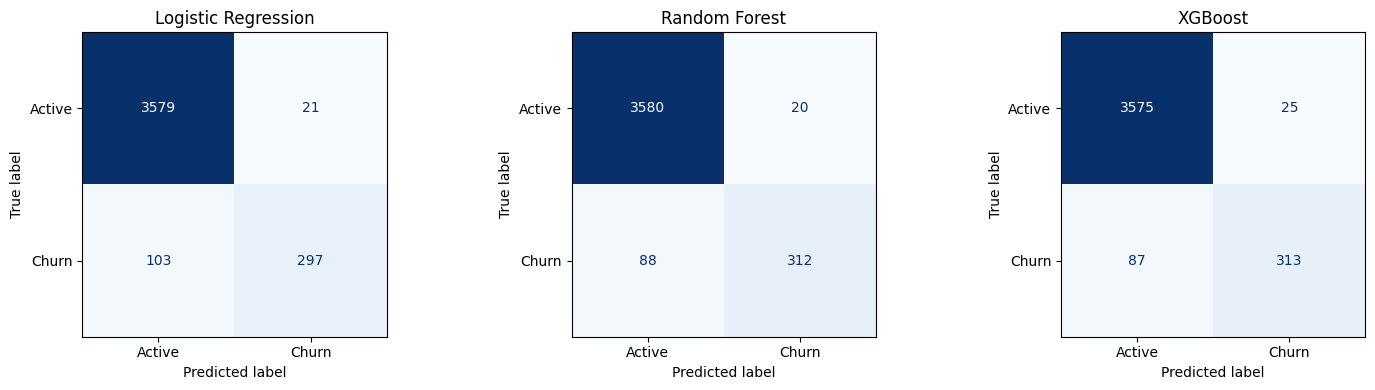

In [ ]:
# Import tools for confusion matrix analysis
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions from the optimized models
logreg_val_pred = best_logreg.predict(X_val_scaled)
rf_val_pred = best_rf.predict(X_val)
xgb_val_pred = best_xgb.predict(X_val)

# Calculate confusion matrices
logreg_cm = confusion_matrix(y_val, logreg_val_pred)
rf_cm = confusion_matrix(y_val, rf_val_pred)
xgb_cm = confusion_matrix(y_val, xgb_val_pred)

# Create a figure for the three confusion matrices
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4),
)

# Display Logistic Regression confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=logreg_cm,
    display_labels=['Active', 'Churn'],
).plot(
    ax=axes[0],
    colorbar=False,
    cmap='Blues',
)
axes[0].set_title('Logistic Regression')

# Display Random Forest confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=['Active', 'Churn'],
).plot(
    ax=axes[1],
    colorbar=False,
    cmap='Blues',
)
axes[1].set_title('Random Forest')

# Display XGBoost confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=['Active', 'Churn'],
).plot(
    ax=axes[2],
    colorbar=False,
    cmap='Blues',
)
axes[2].set_title('XGBoost')

# Adjust the layout and display the figure
plt.tight_layout()
plt.show()

Finding: XGBoost correctly identified 313 out of 400 actual churn customers, with 87 churn customers misclassified as active. Random Forest correctly identified 312 churn customers, while Logistic Regression identified 297. XGBoost had the highest number of correctly identified churn customers, although it also generated more false positives than Random Forest.

### iii. Classification Report

#### Generate Classification Report

In [ ]:
# Import the classification report metric
from sklearn.metrics import classification_report

# Generate classification reports for the optimized models
logreg_report = classification_report(
    y_val,
    logreg_val_pred,
    target_names=['Active', 'Churn'],
)

rf_report = classification_report(
    y_val,
    rf_val_pred,
    target_names=['Active', 'Churn'],
)

xgb_report = classification_report(
    y_val,
    xgb_val_pred,
    target_names=['Active', 'Churn'],
)

# Display the classification reports
print('Logistic Regression')
print(logreg_report)

print('Random Forest')
print(rf_report)

print('XGBoost')
print(xgb_report)

Logistic Regression
              precision    recall  f1-score   support

      Active       0.97      0.99      0.98      3600
       Churn       0.93      0.74      0.83       400

    accuracy                           0.97      4000
   macro avg       0.95      0.87      0.91      4000
weighted avg       0.97      0.97      0.97      4000

Random Forest
              precision    recall  f1-score   support

      Active       0.98      0.99      0.99      3600
       Churn       0.94      0.78      0.85       400

    accuracy                           0.97      4000
   macro avg       0.96      0.89      0.92      4000
weighted avg       0.97      0.97      0.97      4000

XGBoost
              precision    recall  f1-score   support

      Active       0.98      0.99      0.98      3600
       Churn       0.93      0.78      0.85       400

    accuracy                           0.97      4000
   macro avg       0.95      0.89      0.92      4000
weighted avg       0.97      0.9

Finding: Random Forest achieved the highest precision for the Churn class at 0.94, while Random Forest and XGBoost achieved the same recall of 0.78. Logistic Regression showed a lower recall of 0.74, indicating that it identified fewer actual churn customers compared with the other two models.

### iv. ROC Curve & AUC

#### Calculate ROC Curve

In [ ]:
# Import tools for ROC curve analysis
from sklearn.metrics import roc_curve, auc

# Calculate predicted probabilities for the positive class
logreg_val_proba = best_logreg.predict_proba(X_val_scaled)[:, 1]
rf_val_proba = best_rf.predict_proba(X_val)[:, 1]
xgb_val_proba = best_xgb.predict_proba(X_val)[:, 1]

# Calculate ROC curve for each optimized model
logreg_fpr, logreg_tpr, _ = roc_curve(y_val, logreg_val_proba)
rf_fpr, rf_tpr, _ = roc_curve(y_val, rf_val_proba)
xgb_fpr, xgb_tpr, _ = roc_curve(y_val, xgb_val_proba)

# Calculate ROC-AUC for each optimized model
logreg_auc = auc(logreg_fpr, logreg_tpr)
rf_auc = auc(rf_fpr, rf_tpr)
xgb_auc = auc(xgb_fpr, xgb_tpr)

# Review the ROC-AUC scores
print(f'Logistic Regression ROC-AUC: {logreg_auc:.4f}')
print(f'Random Forest ROC-AUC: {rf_auc:.4f}')
print(f'XGBoost ROC-AUC: {xgb_auc:.4f}')

Logistic Regression ROC-AUC: 0.9643
Random Forest ROC-AUC: 0.9685
XGBoost ROC-AUC: 0.9719


#### Visualize ROC Curve

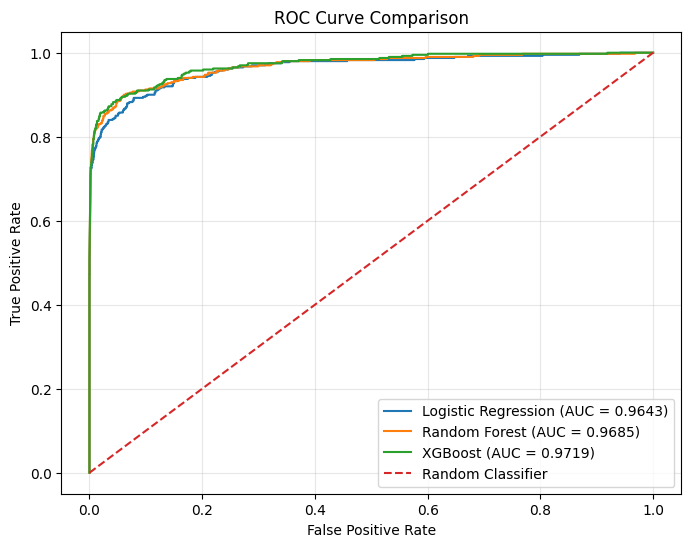

In [ ]:
# Visualize ROC curves for the optimized models
plt.figure(figsize=(8, 6))

# Plot each model's ROC curve
plt.plot(
    logreg_fpr,
    logreg_tpr,
    label=f'Logistic Regression (AUC = {logreg_auc:.4f})',
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.4f})',
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.4f})',
)

# Add the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier',
)

# Add chart labels and title
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)

# Display the ROC curve
plt.show()

Finding: XGBoost achieved the highest ROC-AUC at 0.9719, followed by Random Forest at 0.9685 and Logistic Regression at 0.9643. The ROC curves of all three models remain well above the random classifier line, indicating that the models can effectively distinguish between active and churn customers.

### v. Precision-Recall Curve

#### Calculate Precision-Recall Curve

In [ ]:
# Import tools for precision-recall curve analysis
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision-recall curve for each optimized model
logreg_precision, logreg_recall, _ = precision_recall_curve(
    y_val,
    logreg_val_proba,
)

rf_precision, rf_recall, _ = precision_recall_curve(
    y_val,
    rf_val_proba,
)

xgb_precision, xgb_recall, _ = precision_recall_curve(
    y_val,
    xgb_val_proba,
)

# Calculate average precision score for each optimized model
logreg_ap = average_precision_score(
    y_val,
    logreg_val_proba,
)

rf_ap = average_precision_score(
    y_val,
    rf_val_proba,
)

xgb_ap = average_precision_score(
    y_val,
    xgb_val_proba,
)

# Review the average precision scores
print(f'Logistic Regression AP: {logreg_ap:.4f}')
print(f'Random Forest AP: {rf_ap:.4f}')
print(f'XGBoost AP: {xgb_ap:.4f}')

Logistic Regression AP: 0.8861
Random Forest AP: 0.9023
XGBoost AP: 0.9070


#### Visualize Precision-Recall Curve

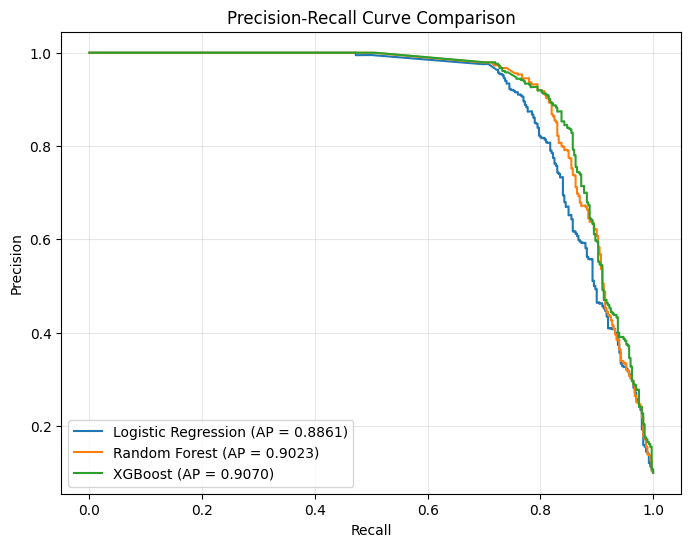

In [ ]:
# Visualize precision-recall curves for the optimized models
plt.figure(figsize=(8, 6))

# Plot each model's precision-recall curve
plt.plot(
    logreg_recall,
    logreg_precision,
    label=f'Logistic Regression (AP = {logreg_ap:.4f})',
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f'Random Forest (AP = {rf_ap:.4f})',
)

plt.plot(
    xgb_recall,
    xgb_precision,
    label=f'XGBoost (AP = {xgb_ap:.4f})',
)

# Add chart labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)

# Display the precision-recall curve
plt.show()

Finding: XGBoost achieved the highest Average Precision at 0.9070, followed by Random Forest at 0.9023 and Logistic Regression at 0.8861. The results indicate that XGBoost provides the strongest precision-recall performance among the three models on the validation set.

### vi. Final Model Selection

#### Review Model Performance

In [ ]:
# Create the final model comparison
final_model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [logreg_tuned_accuracy, rf_tuned_accuracy, xgb_tuned_accuracy],
    'Precision': [logreg_tuned_precision, rf_tuned_precision, xgb_tuned_precision],
    'Recall': [logreg_tuned_recall, rf_tuned_recall, xgb_tuned_recall],
    'F1-score': [logreg_tuned_f1, rf_tuned_f1, xgb_tuned_f1],
    'ROC-AUC': [logreg_tuned_roc_auc, rf_tuned_roc_auc, xgb_tuned_roc_auc],
    'Average Precision': [logreg_ap, rf_ap, xgb_ap],
    'CV ROC-AUC': [logreg_cv_mean, rf_cv_mean, xgb_cv_mean],
})

# Review the final model comparison
final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,CV ROC-AUC
0,Logistic Regression,0.969,0.9340,0.7425,0.8273,0.9643,0.8861,0.9727
1,Random Forest,0.973,0.9398,0.7800,0.8525,0.9685,0.9023,0.9780
2,XGBoost,0.972,0.9260,0.7825,0.8482,0.9719,0.9070,0.9783


Decision: XGBoost is selected as the candidate final model based on its overall validation performance and cross-validation results. It achieved the highest ROC-AUC (0.9719), Average Precision (0.9070), and mean cross-validation ROC-AUC (0.9783), while Random Forest achieved higher accuracy (0.9730), precision (0.9398), and F1-score (0.8525). XGBoost also achieved the highest recall for the Churn class at 0.7825. This trade-off will be considered when interpreting the final model performance.

## **P. Feature Importance & Explainability**

### i. Feature Importance

In [ ]:
# Extract feature importance from the final XGBoost model
xgb_feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb.feature_importances_,
})

# Sort features by importance
xgb_feature_importance = xgb_feature_importance.sort_values(
    'Importance',
    ascending=False,
).reset_index(drop=True)

# Review feature importance
xgb_feature_importance

,Feature,Importance
0,avg_quality_3m,0.457185
1,avg_active_days_3m,0.184403
2,usage_ratio,0.086561
3,total_late_count_6m,0.082309
4,avg_late_payment_days_6m,0.070555
5,complaint_count_6m,0.045486
6,contract_type_Monthly,0.035103
7,avg_resolution_days_6m,0.024638
8,contract_type_12 Month,0.013760
9,contract_type_6 Month,0.000000


Finding: avg_quality_3m was the most important feature in the final XGBoost model, with an importance of 0.457. It was followed by avg_active_days_3m (0.184), usage_ratio (0.087), and total_late_count_6m (0.082). contract_type_6 Month had zero feature importance in the final model.

### ii. Visualize Top Features

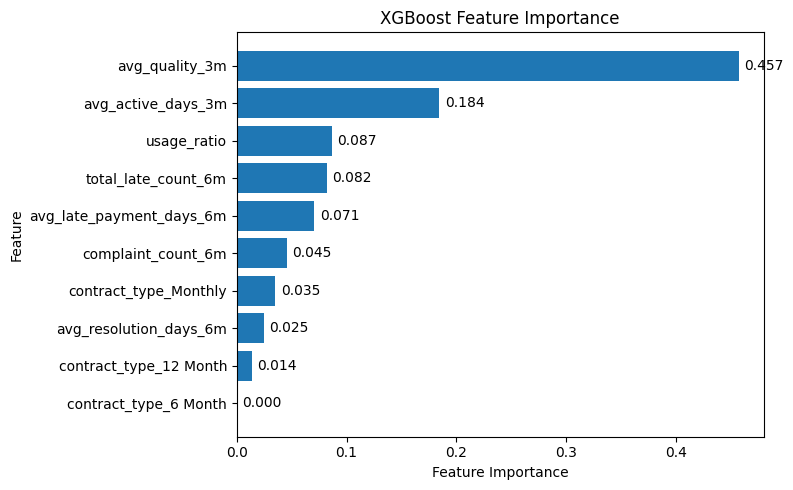

In [ ]:
# Select the top features for visualization
top_features = xgb_feature_importance.head(10)

# Visualize feature importance
plt.figure(figsize=(8, 5))

bars = plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1],
)

# Add importance values to each bar
for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.3f}',
        va='center',
    )

# Add chart labels and title
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance')

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

### iii. SHAP Explainability

#### Import SHAP & Create Explainer

In [ ]:
# Import SHAP for model explainability
import shap

# Create a SHAP TreeExplainer for the final XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Calculate SHAP values on the validation data
shap_values = explainer.shap_values(X_val)

# Check the SHAP value structure
print('SHAP Values shape:', shap_values.shape)

SHAP Values shape: (4000, 10)


#### SHAP Summary Plot

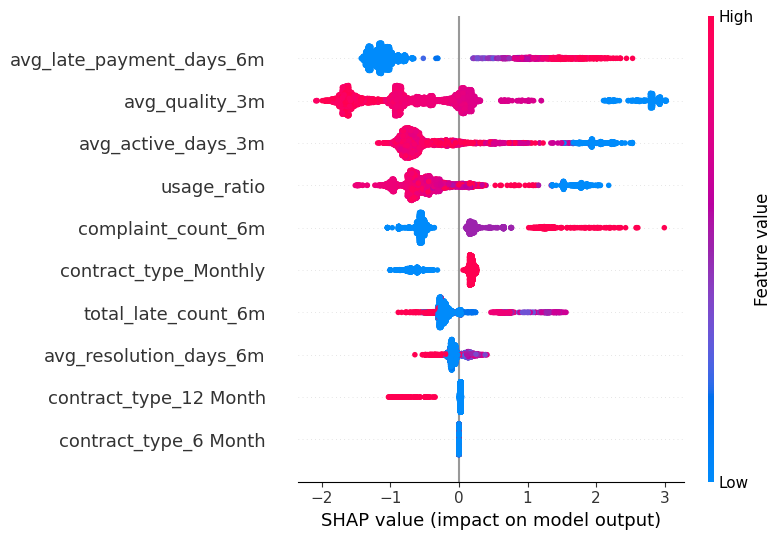

In [ ]:
# Visualize the SHAP summary plot
shap.summary_plot(
    shap_values,
    X_val,
)

Finding: SHAP analysis shows that payment behavior, network quality, customer activity, usage, and complaints contribute to the model's churn predictions. Higher avg_late_payment_days_6m and complaint_count_6m tend to push predictions toward Churn, while lower avg_quality_3m, avg_active_days_3m, and usage_ratio also tend to increase the model's churn prediction.

### iv. SHAP Waterfall for a High-Risk Customer

#### Select High-Risk Customer

In [ ]:
# Identify the highest-risk customer in the validation set
high_risk_index = pd.Series(xgb_val_proba, index=X_val.index).idxmax()

# Get the customer's churn probability
high_risk_probability = xgb_val_proba[
    list(X_val.index).index(high_risk_index)
]

# Get the customer's ID
high_risk_customer_id = df_train_prep.loc[
    high_risk_index,
    'customer_id',
]

# Review the selected customer
print('Customer ID:', high_risk_customer_id)
print(f'Churn probability: {high_risk_probability:.2%}')

Customer ID: CUST010795
Churn probability: 99.95%


#### Generate SHAP Waterfall

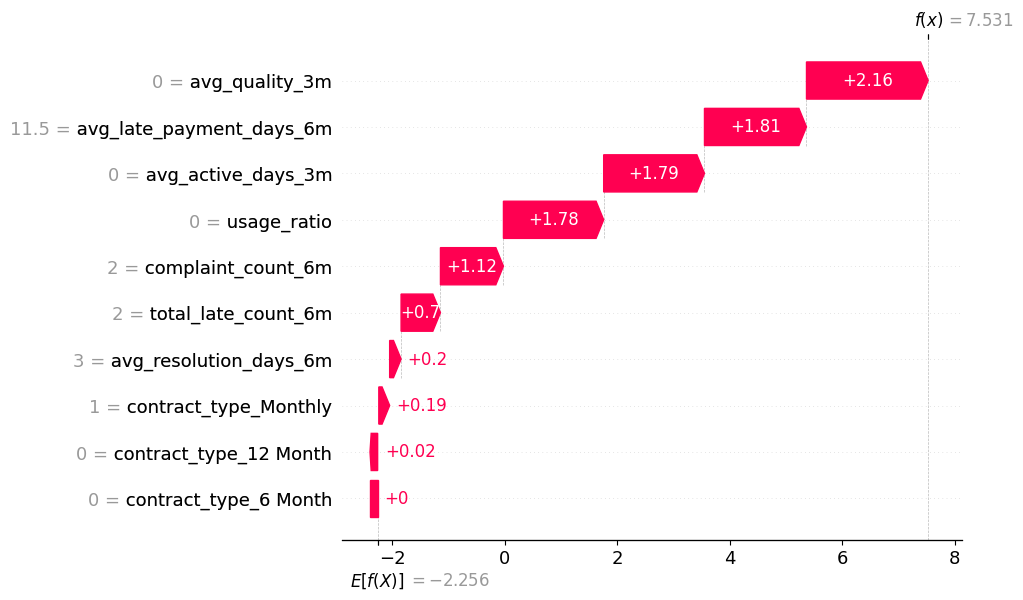

In [ ]:
# Get the validation row for the selected high-risk customer
high_risk_row = X_val.loc[high_risk_index]

# Create a SHAP explanation for the selected customer
high_risk_explanation = shap.Explanation(
    values=shap_values[X_val.index.get_loc(high_risk_index)],
    base_values=explainer.expected_value,
    data=high_risk_row.values,
    feature_names=X_val.columns,
)

# Visualize the SHAP waterfall plot
shap.plots.waterfall(
    high_risk_explanation,
    max_display=10,
)

Finding: For the selected high-risk customer (CUST010795), the model predicted a 99.95% churn probability. The strongest factors pushing the prediction toward churn were low network quality, zero active days, zero usage ratio, and higher late payment days, followed by complaint count and late payment frequency.

## **Q. Test Prediction**

### i. Prepare Test Data

In [ ]:
# Prepare the final test features for prediction
X_test = df_test_encoded.copy()

# Review test feature shape
X_test.shape

(4000, 10)

### ii. Generate Test Predictions

In [ ]:
# Generate churn predictions using the final XGBoost model
y_test_pred = best_xgb.predict(X_test)

# Generate churn probabilities
y_test_proba = best_xgb.predict_proba(X_test)[:, 1]

# Review the churn predictions
print('Test predictions:', y_test_pred.shape)
print('Test probabilities:', y_test_proba.shape)

Test predictions: (4000,)
Test probabilities: (4000,)


### iii. Review Test Prediction Results

In [ ]:
# Count the number of predicted active and churn customers
prediction_counts = pd.Series(y_test_pred).value_counts().sort_index()

# Calculate the percentage of each prediction class
prediction_percentages = pd.Series(y_test_pred).value_counts(normalize=True).sort_index() * 100

# Display the prediction distribution
print('Test Prediction Distribution:')
print(f'Active: {prediction_counts.get(0, 0):,} customers ({prediction_percentages.get(0, 0):.2f}%)')
print(f'Churn: {prediction_counts.get(1, 0):,} customers ({prediction_percentages.get(1, 0):.2f}%)')

Test Prediction Distribution:
Active: 3,676 customers (91.90%)
Churn: 324 customers (8.10%)


Finding: The final XGBoost model predicted 3,676 customers (91.90%) as Active and 324 customers (8.10%) as Churn in the test dataset.

### iv. Create Test Prediction Output

In [ ]:
# Review the available columns in the test dataset
df_test_prep.columns.tolist()

['customer_id',
 'gender',
 'age',
 'city',
 'district',
 'district_tier',
 'join_date',
 'installation_days',
 'tenure_months',
 'household_size',
 'connected_devices',
 'payment_persona',
 'subscription_id',
 'package_speed_mbps',
 'monthly_fee',
 'contract_type',
 'activation_date',
 'complaint_count_6m',
 'avg_resolution_days_6m',
 'avg_satisfaction_score_6m',
 'avg_quality_3m',
 'avg_downtime_3m',
 'avg_latency_3m',
 'avg_late_payment_days_6m',
 'total_late_count_6m',
 'avg_usage_3m',
 'avg_active_days_3m',
 'previous_usage',
 'usage_ratio']

In [ ]:
# Create a dataframe containing the final test predictions
test_prediction_output = pd.DataFrame({
    'customer_id': df_test_prep['customer_id'],
    'churn_prediction': y_test_pred,
    'churn_probability': y_test_proba
})

# Review prediction output
test_prediction_output.head()

,customer_id,churn_prediction,churn_probability
0,CUST020001,0,0.009863
1,CUST020002,1,0.992648
2,CUST020003,0,0.018464
3,CUST020004,0,0.026927
4,CUST020005,0,0.017354


Finding: The prediction output provides each customer's churn classification and churn probability, enabling identification of customers predicted to be at risk of churn.

## **R. Business Recommendations**

### i. Risk-Based Retention Prioritization

#### Identify High-Risk Customers



In [ ]:
# Identify customers predicted as churn by the final XGBoost model
high_risk_customers = test_prediction_output[
    test_prediction_output['churn_probability'] >= 0.50
].copy()

# Sort customers by predicted churn probability
high_risk_customers = high_risk_customers.sort_values('churn_probability', ascending=False)

# Review the number of high-risk customers
print(f'High-risk customers: {len(high_risk_customers):,}')
print(
    f'Percentage of test customers: '
    f'{len(high_risk_customers) / len(test_prediction_output) * 100:.2f}%'
)

# Review the highest-risk customers
high_risk_customers.head(10)

High-risk customers: 324
Percentage of test customers: 8.10%


,customer_id,churn_prediction,churn_probability
3498,CUST023499,1,0.999259
713,CUST020714,1,0.999174
903,CUST020904,1,0.999125
921,CUST020922,1,0.999094
1343,CUST021344,1,0.998955
352,CUST020353,1,0.998925
3547,CUST023548,1,0.998918
1334,CUST021335,1,0.998897
2633,CUST022634,1,0.998844
3614,CUST023615,1,0.998820


#### Identify Individual Risk Drivers

In [ ]:
# Calculate SHAP values for the test dataset
test_shap_values = explainer.shap_values(X_test)

# Check the SHAP value structure
print('Test SHAP values shape:', test_shap_values.shape)

Test SHAP values shape: (4000, 10)


#### Identify Top Risk Driver

In [ ]:
# Create a dataframe containing SHAP contributions for each test customer
test_shap_df = pd.DataFrame(
    test_shap_values,
    columns=X_test.columns,
    index=X_test.index,
)

# Identify the strongest SHAP driver for each customer
test_shap_df['strongest_shap_driver'] = test_shap_df.abs().idxmax(axis=1)

# Keep only the high-risk customer
high_risk_shap = test_shap_df.loc[high_risk_customers.index].copy()

# Add churn probability to the SHAP driver out
high_risk_shap['churn_probability'] = high_risk_customers['churn_probability']

# Review the highest-risk customer SHAP drivers
high_risk_shap.head(10)

,avg_quality_3m,avg_active_days_3m,avg_late_payment_days_6m,total_late_count_6m,complaint_count_6m,usage_ratio,avg_resolution_days_6m,contract_type_12 Month,contract_type_6 Month,contract_type_Monthly,strongest_shap_driver,churn_probability
3498,2.531744,1.797033,1.757972,0.240697,1.108860,1.796831,0.019353,0.020554,0.0,0.190245,avg_quality_3m,0.999259
713,2.124528,1.749900,1.407259,0.764202,1.103369,1.685753,0.308649,0.016890,0.0,0.193991,avg_quality_3m,0.999174
903,2.246304,1.912525,1.865627,0.684782,0.461737,1.727169,0.188718,0.019179,0.0,0.191143,avg_quality_3m,0.999125
921,2.608861,1.966358,1.865627,0.214481,0.468591,1.741817,0.188718,0.018800,0.0,0.189067,avg_quality_3m,0.999094
1343,2.256894,2.185786,1.774812,0.682043,0.450331,1.700725,-0.142208,0.019166,0.0,0.191143,avg_quality_3m,0.998955
352,2.217112,2.155334,1.557819,0.754527,0.455633,1.636776,0.106920,0.015101,0.0,0.191179,avg_quality_3m,0.998925
3547,2.619452,2.239620,1.774812,0.211742,0.457185,1.715373,-0.142208,0.018787,0.0,0.189067,avg_quality_3m,0.998918
1334,2.102523,1.935075,1.176110,0.760953,1.119188,1.659117,0.087691,0.018855,0.0,0.205801,avg_quality_3m,0.998897
2633,2.226313,1.927991,1.489047,0.684782,0.463290,1.709957,0.306432,0.019166,0.0,0.191143,avg_quality_3m,0.998844
3614,2.233717,1.907454,1.612932,0.751410,0.451906,1.639776,0.194726,0.015114,0.0,0.190027,avg_quality_3m,0.998820


#### Create Targeted Customer Groups

In [ ]:
# Count high-risk customers by their strongest SHAP driver
targeted_customer_groups = (
    high_risk_shap['strongest_shap_driver']
    .value_counts()
    .rename_axis('top_driver')
    .reset_index(name='customer_count')
)

# Calculate the percentage of high-risk customers in each group
targeted_customer_groups['percentage'] = (
    targeted_customer_groups['customer_count']
    / len(high_risk_customers)
    * 100
)

# Review the targeted customer groups
targeted_customer_groups

,top_driver,customer_count,percentage
0,avg_quality_3m,287,88.580247
1,avg_late_payment_days_6m,29,8.950617
2,complaint_count_6m,3,0.925926
3,total_late_count_6m,3,0.925926
4,avg_active_days_3m,2,0.617284


In [ ]:
# Get the SHAP contribution of each customer's strongest driver
high_risk_shap['top_driver_shap_value'] = high_risk_shap.apply(
    lambda row: test_shap_df.loc[
        row.name,
        row['strongest_shap_driver'],
    ],
    axis=1,
)

# Review the strongest driver and its SHAP direction
high_risk_shap[
    [
        'strongest_shap_driver',
        'top_driver_shap_value',
        'churn_probability',
    ]
].head(10)

,strongest_shap_driver,top_driver_shap_value,churn_probability
3498,avg_quality_3m,2.531744,0.999259
713,avg_quality_3m,2.124528,0.999174
903,avg_quality_3m,2.246304,0.999125
921,avg_quality_3m,2.608861,0.999094
1343,avg_quality_3m,2.256894,0.998955
352,avg_quality_3m,2.217112,0.998925
3547,avg_quality_3m,2.619452,0.998918
1334,avg_quality_3m,2.102523,0.998897
2633,avg_quality_3m,2.226313,0.998844
3614,avg_quality_3m,2.233717,0.998820


In [ ]:
# Check the SHAP direction of each customer's strongest driver
driver_direction_summary = (
    high_risk_shap
    .assign(
        direction=lambda df: df['top_driver_shap_value'].apply(
            lambda value: 'Pushes toward Churn'
            if value > 0
            else 'Pushes away from Churn'
        )
    )
    .groupby(
        ['strongest_shap_driver', 'direction'],
    )
    .size()
    .reset_index(name='customer_count')
)

# Review the direction of the strongest SHAP drivers
driver_direction_summary

,strongest_shap_driver,direction,customer_count
0,avg_active_days_3m,Pushes toward Churn,2
1,avg_late_payment_days_6m,Pushes toward Churn,29
2,avg_quality_3m,Pushes toward Churn,287
3,complaint_count_6m,Pushes toward Churn,3
4,total_late_count_6m,Pushes toward Churn,3


The final XGBoost model identified 324 high-risk customers (8.10% of the test dataset). Among these customers, avg_quality_3m was the strongest SHAP driver for 287 customers (88.58%), followed by avg_late_payment_days_6m for 29 customers (8.95%). The remaining customers were primarily driven by complaint count, late-payment frequency, and active days. All identified strongest drivers had positive SHAP values, indicating that they contributed to pushing the model's predictions toward Churn.

### ii. Business Recommendations

#### Q1. Who should the business prioritize?

The business should prioritize the 324 customers (8.10% of the test dataset) predicted as high-risk for churn, based on a churn probability of at least 50%.

These customers should be prioritized for retention interventions, with intervention intensity determined by their individual churn probability and key SHAP drivers.

#### Q2. Why are these customers at risk?

Among the 324 high-risk customers, avg_quality_3m was the strongest SHAP driver for 287 customers (88.58%), followed by avg_late_payment_days_6m for 29 customers (8.95%). The remaining customers had complaint count, late-payment frequency, or active days as their strongest SHAP drivers.

This indicates that network quality and payment behavior are the dominant factors contributing to the model's churn predictions for the high-risk group.

#### Q3. Which customers should receive retention campaigns?

Retention campaigns should primarily target the 324 high-risk customers, with interventions tailored to their strongest SHAP drivers rather than applying the same treatment to all customers.

* Network-quality driven → service/network recovery
* Payment-delay driven → payment follow-up or appropriate payment support
* Complaint driven → proactive complaint resolution
* Activity driven → engagement/reactivation initiatives

#### Q4. How can the model support proactive retention?

1. Score customers periodically using the churn model and flag customers with high predicted churn probability.

2. Use the strongest SHAP drivers to route flagged customers toward relevant retention interventions.

3. Monitor post-intervention churn outcomes to evaluate whether the retention strategy reduces actual churn over time.

## **S. Conclusion & Next Steps**

### i. Conclusion

1. The analysis identified several customer characteristics associated with churn, particularly network quality, customer activity, usage, payment behavior, and complaints.

2. After feature selection, hyperparameter optimization, and cross-validation, XGBoost was selected as the final model, achieving 97.20% accuracy, 78.25% recall, 84.82% F1-score, and 97.19% ROC-AUC on the validation set.

3. SHAP analysis showed that avg_quality_3m was the most influential feature in the final model. Among the 324 customers predicted as high-risk in the test set, 287 customers (88.58%) had avg_quality_3m as their strongest SHAP driver.

4. The model can support proactive retention by identifying high-risk customers and providing customer-level risk drivers to help businesses tailor retention interventions.

### ii. Next Steps

1. Deploy the churn model for periodic customer risk scoring and monitoring.

2. Integrate model predictions with customer service or CRM workflows to support targeted retention interventions.

3. Conduct A/B testing to evaluate whether targeted retention interventions reduce actual churn.

4. Retrain and recalibrate the model periodically as customer behavior and network conditions change.

### iii. Methodological Notes

* SHAP values explain the contribution of features to model predictions and should not be interpreted as causal relationships.
* Model performance should be monitored over time as customer behavior and data patterns may change.
* Retention interventions should be evaluated using actual business outcomes, such as churn reduction, rather than model predictions alone.